# **Aprendizaje por refuerzos** - LunarLander (Gymnasium)

## Implementación de un agente DQN (Deep Q-Network): consigna

> **Cómo trabajar este cuaderno.** Hay **3 bloques marcados con `TODO`** repartidos
> por las secciones 6 a 11. Cada uno corta la ejecución con `NotImplementedError`
> hasta que lo completen. Todo lo demás (el entorno, la interfaz, las funciones de
> evaluación y entrenamiento, las gráficas de progreso y el GIF de la sección 9) ya
> está escrito y no hay que tocarlo.

> **Qué se entrega.** Este cuaderno completo y autocontenido, con el código y la
> salida de los experimentos realizados, y un **artículo en formato IEEE** de no más
> de 5 páginas con el informe. La discusión de los resultados va en el artículo, no
> en el cuaderno: la letra de la tarea detalla los puntos que tiene que cubrir.

### Objetivos:
1. Explorar el entorno `LunarLander-v3` de Gymnasium (estado continuo, acciones discretas)
2. Testear el agente aleatorio como implementación de referencia
3. Diseñar e implementar un agente DQN
4. Entrenar y evaluar el agente
5. Comparar el desempeño contra la implementación de referencia y visualizar la política aprendida
6. Medir con un estudio de ablación cuánto aporta cada componente de DQN

El requisito mínimo de la consigna es superar **10% de éxito** en evaluación.

El cuaderno se organiza en una interfaz `Agente`, las funciones `entrenar_agente` /
`evaluar_agente` y el agente DQN, aplicados a un problema de **estado continuo**.
**Versión unificada:** implementación del integrante 2, calibración, evaluación, análisis de política y estudio de ablación. Las celdas de entrenamiento deben ejecutarse para producir resultados en un entorno nuevo.


## 1. Dependencias

| Paquete | Uso |
|---|---|
| `gymnasium[box2d]` | entorno `LunarLander-v3` (el extra `[box2d]` instala también el motor de física) |
| `torch` | red neuronal Q y optimización |
| `matplotlib` | gráficas de progreso y GIF de la política final |

In [1]:
# Instalar los paquetes necesarios. %pip instala en el kernel que está corriendo.
import os
import sys

# >=1.0 porque LunarLander-v3 existe desde ahí; las anteriores registran solo v2.
%pip install -q "gymnasium[box2d]>=1.0" matplotlib pandas scipy
# Aparte y con --index-url para traer la versión de CPU de torch (≈200 MB) y no la
# de CUDA, que es la que pip elegiría por omisión en Linux.
%pip install -q torch --index-url https://download.pytorch.org/whl/cpu

# Sin pantalla (contenedores, CI) SDL necesita este controlador de video para
# poder dibujar los fotogramas del GIF de la sección 9.
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY'):
    os.environ['SDL_VIDEODRIVER'] = 'dummy'

print(f"kernel: {sys.executable}")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
kernel: /home/ismael/AprendizajeAutomatico/.venv/bin/python


In [2]:
# Importar las bibliotecas
import random
import time
from abc import ABC, abstractmethod
from collections import deque, namedtuple

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | "
      f"dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

gymnasium 1.4.0 | torch 2.15.0+cu132 | dispositivo: cpu


## 2. El entorno LunarLander-v3

El objetivo es posar el módulo lunar sobre la plataforma de aterrizaje (siempre en
las coordenadas `(0, 0)`) de forma suave y sin volcarlo.

**Espacio de observación** (`Box(8,)`, continuo):

| Índice | Variable | Significado | Rango |
|---|---|---|---|
| 0 | `x` | posición horizontal respecto de la plataforma | ±2.5 |
| 1 | `y` | altura respecto de la plataforma | ±2.5 |
| 2 | `vx` | velocidad horizontal | ±10 |
| 3 | `vy` | velocidad vertical | ±10 |
| 4 | `θ` | ángulo del módulo | ±2π |
| 5 | `ω` | velocidad angular | ±10 |
| 6 | `c_izq` | 1 si la pata izquierda toca el suelo | 0 o 1 |
| 7 | `c_der` | 1 si la pata derecha toca el suelo | 0 o 1 |

**Espacio de acciones** (`Discrete(4)`): `0` no hacer nada, `1` motor lateral
izquierdo, `2` motor principal, `3` motor lateral derecho.

**Recompensa**, `+10` por cada pata en contacto con el suelo, `−0.3` por cada paso en que se enciende
el motor principal y `−0.03` por cada paso en que se enciende uno lateral. Al final,
`+100` o `−100` según cómo termine el episodio.

**Fin del episodio.** Hay dos casos:

* **Termina** cuando el módulo se estrella o sale de la pantalla (`|x| ≥ 1`), lo que
  da `−100`, o cuando queda quieto sobre el suelo, lo que da `+100`.
* **Se trunca** a los 1000 pasos, por el límite de tiempo que `gym.make` agrega con
  el *wrapper* `TimeLimit`. Truncar no significa que el episodio haya terminado mal:
  simplemente se acabó el presupuesto.

**Criterio de éxito.** La documentación considera resuelto un episodio que acumula
**al menos 200 puntos**. Se usa ese umbral para definir la *tasa de éxito*
(proporción de episodios con recompensa ≥ 200), que es la métrica que se reporta.

In [3]:
# Explorar el entorno LunarLander
env = gym.make('LunarLander-v3')

print("Información del entorno LunarLander-v3:")
print(f"Espacio de observación: {env.observation_space}")
print(f"Espacio de acción:      {env.action_space}")
print(f"Rango de observación:   {env.observation_space.low}")
print(f"                        {env.observation_space.high}")

estado, _ = env.reset(seed=SEMILLA)
print(f"\nEstado inicial: {np.round(estado, 3)}")
print(f"Forma del estado: {estado.shape}, tipo: {estado.dtype}")

accion = env.action_space.sample()
siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)
print(f"\nAcción aleatoria: {accion}")
print(f"Estado siguiente: {np.round(siguiente_estado, 3)}")
print(f"Recompensa: {recompensa:.3f}")
print(f"Terminado: {terminado}, Truncado: {truncado}")

env.close()

Información del entorno LunarLander-v3:
Espacio de observación: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espacio de acción:      Discrete(4)
Rango de observación:   [ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ]
                        [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ]

Estado inicial: [ 0.002  1.418  0.233  0.32  -0.003 -0.053  0.     0.   ]
Forma del estado: (8,), tipo: float32

Acción aleatoria: 1
Estado siguiente: [ 0.004  1.425  0.22   0.295 -0.003 -0.004  0.     0.   ]
Recompensa: 2.080
Terminado: False, Truncado: False


La celda siguiente permite jugar el entorno con el teclado: **W/↑** enciende el motor
principal, **A/←** y **D/→** mueven a los costados, **Q** o **ESC** salen. Sirve
para entender la complejidad del problema.

La llamada queda comentada porque es un bucle que no termina solo: hay que
descomentarla a mano.

In [4]:
def jugar_lunar_lander():
    """Juego interactivo. Controles: W/↑ motor principal, A/← mover a la izquierda,
    D/→ mover a la derecha, ninguna tecla = sin empuje, Q/ESC salir.
    """
    import pygame

    pygame.display.quit()           # obliga a SDL a releer el controlador al reiniciar
    pygame.display.init()
    if pygame.display.get_driver() in ('dummy', 'offscreen'):
        raise RuntimeError(
            'SDL no encontró pantalla. Sin ventana el bucle no recibiría teclas y '
            'colgaría el kernel: hay que correr esta celda en Jupyter local.')

    env = gym.make('LunarLander-v3', render_mode='human')
    env.reset(seed=SEMILLA)
    reloj = pygame.time.Clock()
    recompensa_total = 0.0
    ejecutando = True

    try:
        while ejecutando:
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT or (
                        evento.type == pygame.KEYDOWN
                        and evento.key in (pygame.K_q, pygame.K_ESCAPE)):
                    ejecutando = False

            teclas = pygame.key.get_pressed()
            if teclas[pygame.K_a] or teclas[pygame.K_LEFT]:
                accion = 3                      # motor izq
            elif teclas[pygame.K_d] or teclas[pygame.K_RIGHT]:
                accion = 1                      # motor der
            elif teclas[pygame.K_w] or teclas[pygame.K_UP]:
                accion = 2                      # motor principal
            else:
                accion = 0                      # no hacer nada

            _, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                print(f"Episodio terminado. Recompensa total: {recompensa_total:.1f}")
                recompensa_total = 0.0
                env.reset()

            reloj.tick(50)
    finally:
        env.close()
        pygame.quit()


# Descomentar para jugar (es un bucle interactivo y no termina solo).
# jugar_lunar_lander()

## 3. Interfaz de los agentes

Un agente sabe `elegir_accion` a partir de una observación y `aprender` de una
transición. `elegir_accion` recibe además `explorar`: con `explorar=False` el agente
devuelve la acción que considera mejor, sin exploración; así lo llaman la evaluación
y la grabación del GIF. El agente aleatorio implementa esa interfaz y es la implementación de
referencia contra la que se compara el DQN.

In [5]:
class Agente(ABC):

    @abstractmethod
    def elegir_accion(self, estado, explorar=True):
        """Elige una acción dada una observación. Con `explorar=False`, sin
        exploración: la acción que el agente considera mejor."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass

    def fin_episodio(self):
        """Callback opcional que el bucle de entrenamiento invoca al terminar cada
        episodio."""
        pass


class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar. Es la implementación de referencia."""

    def __init__(self, espacio_acciones, semilla=None):
        self.espacio_acciones = espacio_acciones
        if semilla is not None:
            # El espacio de acciones tiene su propio RNG y no lo alcanzan random.seed
            # ni np.random.seed: sin fijarle la semilla acá, el agente aleatorio no es reproducible.
            espacio_acciones.seed(semilla)

    def elegir_accion(self, estado, explorar=True):
        return self.espacio_acciones.sample()   # no tiene otra política que el azar

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass  # El agente aleatorio no aprende


# Probar el AgenteAleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
estado, _ = env.reset(seed=SEMILLA)
accion = agente_aleatorio.elegir_accion(estado)
print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
env.close()

✓ AgenteAleatorio creado y probado. Acción: 0


## 4. Función de evaluación

`evaluar_agente` corre `num_episodios` episodios completos **sin aprender** y
resume el desempeño. Un episodio se considera **exitoso** si la recompensa
acumulada es **≥ 200**, el umbral de "resuelto" que define Gymnasium para este
entorno.

Las acciones se piden sin exploración (`explorar=False`): la exploración es parte
del entrenamiento, no de la política que se quiere medir.

In [6]:
# Función de evaluación de agentes
UMBRAL_EXITO = 200.0   # recompensa a partir de la cual Gymnasium considera el episodio resuelto


def evaluar_agente(agente, env, num_episodios=100, umbral_exito=UMBRAL_EXITO, semilla=None):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.

    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
        umbral_exito: Recompensa mínima para considerar exitoso un episodio
        semilla: Si se indica, se usan semillas deterministas (semilla + i) para
                 que la comparación entre agentes use los mismos escenarios

    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0

        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                break

        recompensas_totales.append(recompensa_total)

    recompensas_totales = np.array(recompensas_totales)
    exitos = int((recompensas_totales >= umbral_exito).sum())

    return {
        'recompensas_totales': recompensas_totales,
        'exitos': exitos,
        'tasa_exito': exitos / num_episodios,
        'recompensa_promedio': float(recompensas_totales.mean()),
        'desv_estandar': float(recompensas_totales.std()),
        'recompensa_mediana': float(np.median(recompensas_totales)),
    }


def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación con formato."""
    print(f"\n{nombre_agente} - Resultados de evaluación:")
    print(f"Tasa de éxito (R ≥ {UMBRAL_EXITO:.0f}): {resultados['tasa_exito']:.1%}")
    print(f"Recompensa promedio: {resultados['recompensa_promedio']:.2f}")
    print(f"Recompensa mediana:  {resultados['recompensa_mediana']:.2f}")
    print(f"Desviación estándar: {resultados['desv_estandar']:.2f}")
    print(f"Total de éxitos: {resultados['exitos']} / {len(resultados['recompensas_totales'])}")


# Implementación de referencia: evaluar el agente aleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
resultados_aleatorio = evaluar_agente(agente_aleatorio, env, num_episodios=100, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio, "Agente aleatorio")
env.close()


Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -177.53
Recompensa mediana:  -140.74
Desviación estándar: 112.43
Total de éxitos: 0 / 100


## 5. Función de entrenamiento

`entrenar_agente` corre `num_episodios` episodios y, en cada paso, le pasa la
transición al agente con `aprender`, con el indicador `terminado` real (sin
mezclarlo con `truncado`: truncar por tiempo no significa que el valor futuro sea 0).
Al final de cada episodio invoca `agente.fin_episodio()`.

Se agrega además un criterio de parada temprana (`umbral_resolucion`) sobre la
media móvil de 100 episodios, que es el criterio estándar para este entorno.

In [7]:
# Función de entrenamiento de agentes
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=1000, verbose=True,
                    umbral_resolucion=None, semilla=None):
    """
    Entrena un agente en el entorno.

    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
        umbral_resolucion: Si se indica, corta cuando la media de las últimas 100
                           recompensas alcanza ese valor
        semilla: Semilla base para los reset (reproducibilidad)

    Returns:
        (list, list): recompensas y longitudes de cada episodio
    """
    recompensas_episodios = []
    longitudes_episodios = []
    cada = max(1, num_episodios // 20)
    t_inicio = time.time()

    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        pasos = 0

        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

            # `terminado` (y no `terminado or truncado`) es lo que corta el
            # bootstrapping: si el episodio se trunca por tiempo, el valor futuro
            # del estado siguiente sigue siendo válido.
            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado)

            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1

            if terminado or truncado:
                break

        agente.fin_episodio()
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        media_100 = np.mean(recompensas_episodios[-100:])

        if verbose and (episodio + 1) % cada == 0:
            print(f"Episodio {episodio + 1:5d} | Recompensa media (100 ep): {media_100:8.2f} "
                  f"| Longitud media: {np.mean(longitudes_episodios[-100:]):6.1f} "
                  f"| epsilon: {getattr(agente, 'epsilon', 0.0):.3f} "
                  f"| {time.time() - t_inicio:5.0f}s", flush=True)

        if umbral_resolucion is not None and len(recompensas_episodios) >= 100 and media_100 >= umbral_resolucion:
            print(f"\n✓ Entorno resuelto en {episodio + 1} episodios "
                  f"(recompensa media de los últimos 100: {media_100:.2f})", flush=True)
            break

    print(f"Tiempo total de entrenamiento: {time.time() - t_inicio:.0f}s")
    return recompensas_episodios, longitudes_episodios


def media_movil(valores, ventana=100):
    """Media móvil causal, para suavizar las curvas de aprendizaje."""
    valores = np.asarray(valores, dtype=float)
    return np.array([valores[max(0, i - ventana + 1):i + 1].mean() for i in range(len(valores))])


def graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                    titulo="Progreso de entrenamiento", ventana=100):
    """Grafica el progreso del entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    ax1.plot(recompensas_episodios, alpha=0.3, linewidth=0.8, label="Recompensa por episodio")
    ax1.plot(media_movil(recompensas_episodios, ventana), linewidth=2,
             label=f"Media móvil ({ventana} ep)")
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title(f"{titulo} - Recompensas")
    ax1.set_xlabel("Episodio")
    ax1.set_ylabel("Recompensa")
    ax1.legend(loc="lower right", fontsize=8)
    ax1.grid(True, alpha=0.3)

    ax2.plot(longitudes_episodios, alpha=0.3, linewidth=0.8)
    ax2.plot(media_movil(longitudes_episodios, ventana), linewidth=2)
    ax2.set_title(f"{titulo} - Longitud de los episodios")
    ax2.set_xlabel("Episodio")
    ax2.set_ylabel("Pasos")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


print("✓ Funciones de entrenamiento definidas")

✓ Funciones de entrenamiento definidas


## 6. El agente DQN

La celda siguiente define el agente DQN a implementar.


In [8]:
# Implementación del agente DQN
class RedQ(nn.Module):
    """Perceptrón multicapa que aproxima Q(s, ·): recibe el estado (8 dimensiones)
    y devuelve un valor Q por cada acción (4), todo en una sola pasada."""

    def __init__(self, dim_estado, num_acciones, neuronas=(128, 128)):
        super().__init__()
        capas, entrada = [], dim_estado
        for n in neuronas:
            capas += [nn.Linear(entrada, n), nn.ReLU()]
            entrada = n
        capas.append(nn.Linear(entrada, num_acciones))   # salida lineal: Q no está acotado
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x)


class BufferReplay:
    """Memoria de experiencias circular, con arreglos preasignados de NumPy.
    Al llenarse, las transiciones nuevas pisan las más viejas."""

    def __init__(self, capacidad, dim_estado):
        self.capacidad = capacidad
        self.estados = np.zeros((capacidad, dim_estado), dtype=np.float32)
        self.acciones = np.zeros(capacidad, dtype=np.int64)
        self.recompensas = np.zeros(capacidad, dtype=np.float32)
        self.siguientes = np.zeros((capacidad, dim_estado), dtype=np.float32)
        self.terminados = np.zeros(capacidad, dtype=np.float32)
        self.pos = 0
        self.tam = 0

    def __len__(self):
        return self.tam

    def agregar(self, estado, accion, recompensa, siguiente, terminado):
        i = self.pos
        self.estados[i], self.acciones[i], self.recompensas[i] = estado, accion, recompensa
        self.siguientes[i], self.terminados[i] = siguiente, float(terminado)
        self.pos = (self.pos + 1) % self.capacidad
        self.tam = min(self.tam + 1, self.capacidad)

    def muestrear(self, tam_lote, rng):
        idx = rng.integers(0, self.tam, size=tam_lote)   # uniforme, con reposición
        return (self.estados[idx], self.acciones[idx], self.recompensas[idx],
                self.siguientes[idx], self.terminados[idx])


class AgenteDQN(Agente):
    """Agente de Red Q Profunda.

    `semilla` fija los generadores (random, NumPy, PyTorch y `accion_space.seed`).
    `elegir_accion(estado, explorar=False)` devuelve la acción greedy, sin explorar.
    `fin_episodio()` se invoca al terminar cada episodio de entrenamiento.

    Interruptores de la ablación (sección 11):
      * `usar_replay=False`: DQN online. No hay buffer: cada transición se usa una
        sola vez, en un lote de tamaño 1, justo cuando ocurre.
      * `usar_target=False`: el objetivo temporal se calcula con la propia red
        online (no existe la red objetivo).
      * ambos en False: Q-learning online con red neuronal, sin ninguna de las dos
        técnicas de estabilización.
    """

    def __init__(self, estado_space, accion_space, semilla=None,
                 tasa_aprendizaje=5e-4, gamma=0.99,
                 epsilon_inicial=1.0, epsilon_final=0.01, decaimiento_epsilon=0.995,
                 tam_buffer=100_000, tam_lote=64, pasos_calentamiento=1_000,
                 frecuencia_entrenamiento=1, frecuencia_target=1_000,
                 neuronas=(128, 128), norma_gradiente=10.0,
                 usar_replay=True, usar_target=True, dispositivo='cpu'):
        self.accion_space = accion_space
        self.dim_estado = int(estado_space.shape[0])
        self.num_acciones = int(accion_space.n)

        # Hiperparámetros (todos configurables para la calibración y la ablación)
        self.tasa_aprendizaje = tasa_aprendizaje
        self.gamma = gamma
        self.epsilon = epsilon_inicial
        self.epsilon_final = epsilon_final
        self.decaimiento_epsilon = decaimiento_epsilon       # multiplicativo, por episodio
        self.tam_lote = tam_lote
        self.pasos_calentamiento = max(pasos_calentamiento, tam_lote)
        self.frecuencia_entrenamiento = frecuencia_entrenamiento   # cada cuántos pasos se actualiza
        self.frecuencia_target = frecuencia_target                 # cada cuántas actualizaciones se copia la red
        self.norma_gradiente = norma_gradiente
        self.usar_replay = usar_replay
        self.usar_target = usar_target
        self.dispositivo = torch.device(dispositivo)

        # Semillas: random, NumPy, PyTorch y el RNG propio del espacio de acciones.
        # Además se usa un Generator local para el sorteo de ε y del minibatch.
        self.semilla = semilla
        if semilla is not None:
            random.seed(semilla)
            np.random.seed(semilla)
            torch.manual_seed(semilla)
            accion_space.seed(semilla)
        self.rng = np.random.default_rng(semilla)

        # Red Q online y (opcional) red objetivo con los mismos pesos iniciales
        self.red_q = RedQ(self.dim_estado, self.num_acciones, neuronas).to(self.dispositivo)
        if usar_target:
            self.red_objetivo = RedQ(self.dim_estado, self.num_acciones, neuronas).to(self.dispositivo)
            self.red_objetivo.load_state_dict(self.red_q.state_dict())
            self.red_objetivo.eval()          # la red objetivo nunca se entrena
        else:
            self.red_objetivo = None
        self.optimizador = optim.Adam(self.red_q.parameters(), lr=tasa_aprendizaje)

        # Memoria de experiencias: solo existe en la variante con replay
        self.buffer = BufferReplay(tam_buffer, self.dim_estado) if usar_replay else None

        # Contadores y trazas para diagnóstico y pruebas
        self.pasos = 0                 # transiciones vistas
        self.actualizaciones = 0       # pasos de gradiente realizados
        self.ultima_perdida = None
        self.ultimo_lote = None        # último lote usado en una actualización

    # Política
    def elegir_accion(self, estado, explorar=True):
        """ε-greedy. Con `explorar=False` devuelve siempre la acción de mayor Q."""

        if explorar and self.rng.random() < self.epsilon:
            return int(self.accion_space.sample())          # acción aleatoria (RNG sembrado)
        with torch.no_grad():                                # sin gradientes al actuar
            s = torch.as_tensor(estado, dtype=torch.float32, device=self.dispositivo).unsqueeze(0)
            return int(self.red_q(s).argmax(dim=1).item())

    # Aprendizaje
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Almacena la experiencia y entrena la red."""

        self.pasos += 1

        if self.usar_replay:
            self.buffer.agregar(estado, accion, recompensa, siguiente_estado, terminado)
            if len(self.buffer) < self.pasos_calentamiento:
                return                                       # calentamiento: solo se acumula
            if self.pasos % self.frecuencia_entrenamiento != 0:
                return
            lote = self.buffer.muestrear(self.tam_lote, self.rng)
        else:
            # Sin replay: se aprende solo de la transición actual (lote de tamaño 1)
            if self.pasos % self.frecuencia_entrenamiento != 0:
                return
            lote = (np.asarray(estado, dtype=np.float32)[None, :],
                    np.asarray([accion], dtype=np.int64),
                    np.asarray([recompensa], dtype=np.float32),
                    np.asarray(siguiente_estado, dtype=np.float32)[None, :],
                    np.asarray([float(terminado)], dtype=np.float32))

        self._actualizar(lote)

    def _calcular_objetivo(self, recompensas, siguientes, terminados):
        """y = r + γ · max_a' Q_objetivo(s', a') · (1 − terminado).

        `terminados` marca solo la terminación real: en los estados terminales el
        valor futuro es 0, pero un episodio truncado por tiempo sí hace bootstrapping.
        Sin red objetivo, el máximo se calcula con la propia red online."""

        red = self.red_objetivo if self.usar_target else self.red_q
        with torch.no_grad():                                # el objetivo no propaga gradiente
            q_siguiente = red(siguientes).max(dim=1).values
        return recompensas + self.gamma * q_siguiente * (1.0 - terminados)

    def _actualizar(self, lote):
        """Un paso de gradiente sobre un lote (estados, acciones, recompensas, siguientes, terminados)."""

        estados, acciones, recompensas, siguientes, terminados = (
            torch.as_tensor(x, device=self.dispositivo) for x in lote)
        self.ultimo_lote = lote

        # Q(s, a) de la acción efectivamente tomada: (B, 4) -> gather -> (B,)
        q_sa = self.red_q(estados).gather(1, acciones.unsqueeze(1)).squeeze(1)
        objetivo = self._calcular_objetivo(recompensas, siguientes, terminados)

        perdida = F.smooth_l1_loss(q_sa, objetivo)           # Huber: robusta a recompensas grandes
        self.optimizador.zero_grad()
        perdida.backward()
        nn.utils.clip_grad_norm_(self.red_q.parameters(), self.norma_gradiente)
        self.optimizador.step()

        self.actualizaciones += 1
        self.ultima_perdida = float(perdida.item())
        if self.usar_target and self.actualizaciones % self.frecuencia_target == 0:
            self.sincronizar_target()

    def sincronizar_target(self):
        """Copia los pesos de la red online en la red objetivo (actualización dura)."""
        if self.red_objetivo is not None:
            self.red_objetivo.load_state_dict(self.red_q.state_dict())

    def fin_episodio(self):
        """El bucle de entrenamiento lo invoca al terminar cada episodio."""
        self.epsilon = max(self.epsilon_final, self.epsilon * self.decaimiento_epsilon)

    # Guardar / cargar
    def guardar(self, ruta):
        """Guarda los pesos de la red Q (y de la objetivo, si existe)."""
        torch.save({'red_q': self.red_q.state_dict(),
                    'red_objetivo': None if self.red_objetivo is None else self.red_objetivo.state_dict(),
                    'epsilon': self.epsilon}, ruta)

    def cargar(self, ruta):
        """Carga pesos guardados con `guardar`."""
        datos = torch.load(ruta, map_location=self.dispositivo)
        self.red_q.load_state_dict(datos['red_q'])
        if self.red_objetivo is not None:
            self.red_objetivo.load_state_dict(datos['red_objetivo'] or datos['red_q'])
        self.epsilon = datos['epsilon']

### Decisiones de diseño del `AgenteDQN`

* **Red Q:** perceptrón multicapa `8 → 128 → 128 → 4` con ReLU y salida lineal. Una sola pasada devuelve el valor Q de las 4 acciones.
* **Objetivo temporal:** `y = r + γ · max_a' Q_objetivo(s', a') · (1 − terminado)`. Solo `terminado` corta el *bootstrapping*, un episodio truncado por tiempo no lo corta (coincide con lo que le pasa `entrenar_agente`).
* **Optimización:** pérdida de Huber (`smooth_l1`), Adam y recorte de la norma del gradiente.
* **Replay:** buffer circular de NumPy con muestreo uniforme y un período de calentamiento antes de empezar a entrenar.
* **Red objetivo:** copia de la red online, actualizada de forma *dura* cada `frecuencia_target` actualizaciones.
* **Exploración:** ε-greedy con decaimiento multiplicativo por episodio (se aplica en `fin_episodio`). Con `explorar=False` el agente es siempre greedy.
* **Reproducibilidad:** `semilla` fija `random`, NumPy, PyTorch y `accion_space.seed`; el sorteo de ε y el muestreo del minibatch usan además un `Generator` propio.
* **Interruptores de la ablación:** `usar_replay=False` (sin buffer, cada transición se usa una sola vez en un lote de tamaño 1) y `usar_target=False` (el objetivo se calcula con la red online). Los hiperparámetros por defecto son solo un punto de partida: la calibración se hace aparte.

Las celdas siguientes son pruebas rápidas de que el agente hace lo que dice (acción, objetivo temporal, actualización y sincronización, variantes, reproducibilidad y guardado).

In [9]:
# Pruebas rápidas (de humo) del AgenteDQN: tardan unos segundos y no entrenan en serio.
import tempfile, os


def _nuevo_agente(**kwargs):
    """Crea un agente con su propio entorno (solo para obtener los espacios)."""

    env = gym.make('LunarLander-v3')
    kwargs.setdefault('semilla', 0)
    return AgenteDQN(env.observation_space, env.action_space, **kwargs)


def _correr_pasos(agente, n_pasos, semilla_env=0):
    """Interactúa `n_pasos` con el entorno y entrena al agente en cada paso."""

    env = gym.make('LunarLander-v3')
    estado, _ = env.reset(seed=semilla_env)
    for _ in range(n_pasos):
        accion = agente.elegir_accion(estado)
        siguiente, recompensa, terminado, truncado, _ = env.step(accion)
        agente.aprender(estado, accion, recompensa, siguiente, terminado)
        estado = siguiente
        if terminado or truncado:
            estado, _ = env.reset()
    env.close()


def _pesos(red):
    """Todos los parámetros de una red, aplanados en un único vector (copia)."""

    return torch.cat([p.detach().flatten() for p in red.parameters()]).clone()


# 1. Elección de acción: greedy determinista y exploración
agente = _nuevo_agente()
estado = np.zeros(8, dtype=np.float32)
greedy = {agente.elegir_accion(estado, explorar=False) for _ in range(50)}
assert len(greedy) == 1 and greedy.pop() in range(4)
agente.epsilon = 1.0
assert len({agente.elegir_accion(estado) for _ in range(300)}) == 4, "con ε=1 deben salir las 4 acciones"
assert len({agente.elegir_accion(estado, explorar=False) for _ in range(50)}) == 1, \
    "con explorar=False debe ser greedy aunque ε=1"
agente.epsilon = 0.0
assert agente.elegir_accion(estado) == agente.elegir_accion(estado, explorar=False)
print("✓ 1. elegir_accion: greedy sin exploración, ε-greedy con exploración")

# 2. Objetivo temporal: terminales, truncados y red objetivo
agente = _nuevo_agente(gamma=0.9)
r = torch.tensor([1.0, 1.0]); sig = torch.randn(2, 8); term = torch.tensor([1.0, 0.0])
y = agente._calcular_objetivo(r, sig, term)
q_max = agente.red_objetivo(sig).max(dim=1).values
assert torch.allclose(y[0], r[0]), "en un estado terminal el objetivo es solo la recompensa"
assert torch.allclose(y[1], r[1] + 0.9 * q_max[1]), "si no es terminal: r + γ·max Q_objetivo(s')"
assert not y.requires_grad, "el objetivo no debe propagar gradiente"
y_antes = agente._calcular_objetivo(r, sig, term)
with torch.no_grad():
    for p in agente.red_q.parameters():
        p.add_(1.0)                                   # se mueve solo la red online
assert torch.allclose(y_antes, agente._calcular_objetivo(r, sig, term)), "la red objetivo está congelada"
print("✓ 2. objetivo temporal: (1 − terminado) correcto, sin gradiente y con red objetivo congelada")

# 3. La red online se actualiza y la objetivo se sincroniza cada N pasos
agente = _nuevo_agente(tam_lote=32, pasos_calentamiento=32, frecuencia_target=20)
inicial = _pesos(agente.red_q)
_correr_pasos(agente, 31)
assert agente.actualizaciones == 0 and torch.equal(_pesos(agente.red_q), inicial), "no se entrena en el calentamiento"
_correr_pasos(agente, 9)
assert agente.actualizaciones == 9 and not torch.equal(_pesos(agente.red_q), inicial), "los pesos online cambian"
assert torch.equal(_pesos(agente.red_objetivo), inicial), "la red objetivo sigue congelada entre sincronizaciones"
_correr_pasos(agente, 11)
assert agente.actualizaciones == 20 and torch.equal(_pesos(agente.red_objetivo), _pesos(agente.red_q)), \
    "tras frecuencia_target actualizaciones, la red objetivo copia a la online"
print("✓ 3. optimización: la red online cambia y la objetivo se sincroniza cada `frecuencia_target`")

# 4. Variante sin replay: solo usa la transición actual
agente = _nuevo_agente(usar_replay=False)
assert agente.buffer is None
env = gym.make('LunarLander-v3'); estado, _ = env.reset(seed=0)
for _ in range(30):
    accion = agente.elegir_accion(estado)
    siguiente, recompensa, terminado, truncado, _ = env.step(accion)
    agente.aprender(estado, accion, recompensa, siguiente, terminado)
    lote = agente.ultimo_lote
    assert lote[0].shape == (1, 8) and np.allclose(lote[0][0], estado) and np.allclose(lote[3][0], siguiente) \
        and lote[1][0] == accion and np.isclose(lote[2][0], recompensa), "el lote debe ser la transición actual"
    estado = siguiente
env.close()
assert agente.actualizaciones == 30, "aprende en cada paso, desde el primero"
agente = _nuevo_agente(tam_lote=32, pasos_calentamiento=32)       # contraste: con replay
_correr_pasos(agente, 100)
assert len(agente.buffer) == 100 and agente.ultimo_lote[0].shape == (32, 8)
print("✓ 4. sin replay: lote de tamaño 1 con la transición actual y sin buffer; con replay: lotes de 32")

# 5. Variante sin red objetivo
agente = _nuevo_agente(usar_target=False)
assert agente.red_objetivo is None
y_antes = agente._calcular_objetivo(r, sig, term)
with torch.no_grad():
    for p in agente.red_q.parameters():
        p.add_(1.0)
assert not torch.allclose(y_antes, agente._calcular_objetivo(r, sig, term)), "el objetivo sigue a la red online"
agente.sincronizar_target()                                        # no debe fallar ni hacer nada
_correr_pasos(agente, 50)
print("✓ 5. sin red objetivo: el objetivo se calcula con la propia red online")

# 6. Reproducibilidad
def _entrenar_corto(semilla):
    agente = _nuevo_agente(semilla=semilla, tam_lote=32, pasos_calentamiento=32)
    _correr_pasos(agente, 150)
    return _pesos(agente.red_q)

assert torch.equal(_entrenar_corto(7), _entrenar_corto(7)), "misma semilla ⇒ mismos pesos"
assert not torch.equal(_entrenar_corto(7), _entrenar_corto(8)), "semillas distintas ⇒ pesos distintos"
print("✓ 6. reproducibilidad: misma semilla da exactamente los mismos pesos")

# 7. Guardar y cargar
agente = _nuevo_agente(semilla=1); _correr_pasos(agente, 40)
otro = _nuevo_agente(semilla=2)
ruta_tmp = os.path.join(tempfile.mkdtemp(), 'dqn_prueba.pt')
agente.guardar(ruta_tmp); otro.cargar(ruta_tmp)
prueba = torch.randn(16, 8)
assert torch.allclose(agente.red_q(prueba), otro.red_q(prueba)), "la red cargada debe dar los mismos Q"
print("✓ 7. guardar/cargar: la red recuperada produce los mismos valores Q")

# 8. Entrenar y evaluar unos episodios en las 4 configuraciones de la ablación
configuraciones = {
    'DQN completo':     dict(usar_replay=True,  usar_target=True),
    'sin replay':       dict(usar_replay=False, usar_target=True),
    'sin red objetivo': dict(usar_replay=True,  usar_target=False),
    'sin ambos':        dict(usar_replay=False, usar_target=False),
}
print(f"\n{'configuración':<18} {'ep. entrenados':>14} {'actualizaciones':>16} {'tam. buffer':>12} {'R eval. (media)':>16}")
for nombre, cfg in configuraciones.items():
    env = gym.make('LunarLander-v3')
    agente = AgenteDQN(env.observation_space, env.action_space, semilla=0,
                       pasos_calentamiento=64, **cfg)
    entrenar_agente(agente, env, num_episodios=3, max_pasos=200, verbose=False, semilla=0)
    res = evaluar_agente(agente, env, num_episodios=2, semilla=10_000)
    env.close()
    tam_buffer = 0 if agente.buffer is None else len(agente.buffer)
    print(f"{nombre:<18} {3:>14} {agente.actualizaciones:>16} {tam_buffer:>12} {res['recompensa_promedio']:>16.1f}")
print("\n✓ 8. las cuatro configuraciones entrenan y evalúan sin excepciones")

✓ 1. elegir_accion: greedy sin exploración, ε-greedy con exploración
✓ 2. objetivo temporal: (1 − terminado) correcto, sin gradiente y con red objetivo congelada
✓ 3. optimización: la red online cambia y la objetivo se sincroniza cada `frecuencia_target`
✓ 4. sin replay: lote de tamaño 1 con la transición actual y sin buffer; con replay: lotes de 32
✓ 5. sin red objetivo: el objetivo se calcula con la propia red online
✓ 6. reproducibilidad: misma semilla da exactamente los mismos pesos
✓ 7. guardar/cargar: la red recuperada produce los mismos valores Q

configuración      ep. entrenados  actualizaciones  tam. buffer  R eval. (media)
Tiempo total de entrenamiento: 0s
DQN completo                    3              204          267           -648.5
Tiempo total de entrenamiento: 0s
sin replay                      3              291            0           -818.7
Tiempo total de entrenamiento: 0s
sin red objetivo                3              204          267           -565.3
Tiempo total 

## 6b. Calibración de hiperparámetros

Barrido por etapas: en cada etapa se varía **un** hiperparámetro y los demás quedan en
el valor elegido hasta ese momento.

| Etapa | Hiperparámetro | Valores |
|---|---|---|
| A | `tasa_aprendizaje` | 1e-4, 5e-4, 1e-3 |
| B | `frecuencia_target` (actualizaciones entre copias) | 250, 1000, 4000 |
| C | `frac_exploracion` (fracción del entrenamiento en que ε llega a su mínimo) | 0.3, 0.5, 0.75 |

**Protocolo, fijado antes de ver los resultados.**

* Cada configuración se entrena `EPISODIOS_CALIB` episodios con las semillas de agente
  `SEMILLAS_CALIB`; los `reset` de entrenamiento usan `100000·semilla + episodio`.
* Se evalúa sin exploración en `EPISODIOS_EVAL_CALIB` episodios con semillas
  `50000…`, disjuntas de la evaluación final (`10000…10199`) y de las del GIF
  (`20000…29999`).
* Métrica: recompensa media de evaluación, promediada entre semillas. Se adopta un valor
  nuevo solo si supera al vigente por más de un error estándar combinado; si no, se
  conserva el vigente.
* ε decae por episodio, así que el mismo `decaimiento_epsilon` explora distinto con
  presupuestos distintos. Por eso se calibra `frac_exploracion` y de ella se deduce
  `decaimiento_epsilon` para cada presupuesto (`kwargs_agente`).
* Cada corrida se agrega a `resultados/calibracion.csv` apenas termina; las curvas van a
  `resultados/curvas_calibracion/`. Una corrida que ya está en el CSV no se repite.

In [10]:
# Calibración (1/5): protocolo, ejecución en paralelo y registro en disco
import contextlib, hashlib, io, json
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import pandas as pd
from IPython.display import display

# True: corrida mínima de punta a punta (pocos minutos) para comprobar que todo funciona.
# Sus resultados van a otra carpeta y no se mezclan con los reales.
MODO_PRUEBA = False

DIR_RESULTADOS = Path('resultados_prueba' if MODO_PRUEBA else 'resultados')
DIR_CURVAS = DIR_RESULTADOS / 'curvas_calibracion'
DIR_CURVAS.mkdir(parents=True, exist_ok=True)
CSV_CALIBRACION = DIR_RESULTADOS / 'calibracion.csv'

EPISODIOS_CALIB      = 25 if MODO_PRUEBA else 600
SEMILLAS_CALIB       = [1, 2] if MODO_PRUEBA else [1, 2, 3]
EPISODIOS_EVAL_CALIB = 3 if MODO_PRUEBA else 50
SEMILLA_EVAL_CALIB   = 50_000      # 50000…50049: disjuntas de la evaluación final y del GIF
EPSILON_INICIAL, EPSILON_FINAL = 1.0, 0.01

# Varias corridas a la vez solo en Linux (Colab incluido), donde se puede usar `fork`
# desde un cuaderno. En macOS/Windows se corre en serie.
N_PROCESOS = max(1, (os.cpu_count() or 2) - 1) if sys.platform.startswith('linux') else 1

# Punto de partida: los valores por defecto del AgenteDQN. frac_exploracion = 0.75
# equivale aproximadamente a decaimiento_epsilon = 0.995 con 1200 episodios.
CONFIG_BASE = dict(frac_exploracion=0.75, frecuencia_target=1_000, tasa_aprendizaje=5e-4)


def kwargs_agente(config, num_episodios):
    """Traduce una configuración de calibración a argumentos de AgenteDQN.
    `frac_exploracion` se convierte en el `decaimiento_epsilon` que lleva ε de
    EPSILON_INICIAL a EPSILON_FINAL en esa fracción de `num_episodios`."""
    kw = {k: v for k, v in config.items() if k != 'frac_exploracion'}
    n = max(1.0, config.get('frac_exploracion', 0.75) * num_episodios)
    kw.update(epsilon_inicial=EPSILON_INICIAL, epsilon_final=EPSILON_FINAL,
              decaimiento_epsilon=(EPSILON_FINAL / EPSILON_INICIAL) ** (1.0 / n))
    return kw


def _texto(config):
    return json.dumps(config, sort_keys=True)


def _clave(config, semilla, num_episodios):
    return _texto({'config': config, 'semilla': semilla, 'episodios': num_episodios})


def correr_configuracion(config, semilla, num_episodios):
    """Entrena una configuración con una semilla, la evalúa sin exploración y devuelve
    una fila con los resultados. La curva de entrenamiento se guarda en disco."""
    hilos = torch.get_num_threads()
    torch.set_num_threads(1)                   # varios procesos a la vez: un hilo cada uno
    try:
        env = gym.make('LunarLander-v3')
        agente = AgenteDQN(env.observation_space, env.action_space, semilla=semilla,
                           **kwargs_agente(config, num_episodios))
        t0 = time.time()
        with contextlib.redirect_stdout(io.StringIO()):      # silencia el resumen final
            recompensas, longitudes = entrenar_agente(
                agente, env, num_episodios=num_episodios, verbose=False,
                semilla=100_000 * semilla)
        tiempo = time.time() - t0
        ev = evaluar_agente(agente, env, num_episodios=EPISODIOS_EVAL_CALIB,
                            semilla=SEMILLA_EVAL_CALIB)
        env.close()
    finally:
        torch.set_num_threads(hilos)

    clave = _clave(config, semilla, num_episodios)
    ruta_curva = DIR_CURVAS / f"{hashlib.md5(clave.encode()).hexdigest()[:12]}.npz"
    np.savez(ruta_curva, recompensas=np.array(recompensas), longitudes=np.array(longitudes))
    return dict(clave=clave, config=_texto(config), **config, semilla=semilla,
                episodios=num_episodios, pasos_totales=int(np.sum(longitudes)),
                tiempo_s=round(tiempo, 1),
                recompensa_eval=ev['recompensa_promedio'],
                mediana_eval=ev['recompensa_mediana'],
                tasa_exito_eval=ev['tasa_exito'],
                recompensa_entr_ult100=float(np.mean(recompensas[-100:])),
                curva=str(ruta_curva))


def ejecutar_corridas(configs, semillas=None, num_episodios=None):
    """Corre (en paralelo si se puede) las combinaciones configuración × semilla que
    todavía no están en el CSV y devuelve las filas de todas ellas."""
    semillas = semillas or SEMILLAS_CALIB
    num_episodios = num_episodios or EPISODIOS_CALIB
    hechas = set(pd.read_csv(CSV_CALIBRACION)['clave']) if CSV_CALIBRACION.exists() else set()
    pendientes = [(c, s) for c in configs for s in semillas
                  if _clave(c, s, num_episodios) not in hechas]
    print(f"{len(configs) * len(semillas)} corridas ({len(pendientes)} pendientes), "
          f"{num_episodios} episodios cada una, {N_PROCESOS} proceso(s)", flush=True)

    def registrar(fila):
        fila_df = pd.DataFrame([fila])
        if CSV_CALIBRACION.exists():
            # mismas columnas y en el mismo orden que el encabezado ya escrito
            fila_df = fila_df[pd.read_csv(CSV_CALIBRACION, nrows=0).columns]
        fila_df.to_csv(CSV_CALIBRACION, mode='a', header=not CSV_CALIBRACION.exists(), index=False)
        print(f"  ✓ {fila['config']} semilla {fila['semilla']}: R_eval = {fila['recompensa_eval']:7.1f}, "
              f"éxito = {fila['tasa_exito_eval']:4.0%}, {fila['tiempo_s'] / 60:.1f} min", flush=True)

    t0 = time.time()
    if N_PROCESOS == 1 or len(pendientes) <= 1:
        for c, s in pendientes:
            registrar(correr_configuracion(c, s, num_episodios))
    else:
        with ProcessPoolExecutor(max_workers=N_PROCESOS, mp_context=mp.get_context('fork')) as ex:
            futuros = [ex.submit(correr_configuracion, c, s, num_episodios) for c, s in pendientes]
            for f in as_completed(futuros):
                registrar(f.result())
    if pendientes:
        print(f"Tiempo de la etapa: {(time.time() - t0) / 60:.1f} min")

    todas = pd.read_csv(CSV_CALIBRACION)
    claves = {_clave(c, s, num_episodios) for c in configs for s in semillas}
    return todas[todas['clave'].isin(claves)].copy()


def resumir(df, param):
    """Una fila por valor del hiperparámetro: media, desvío y error estándar entre semillas."""
    res = df.groupby('config').agg(
        valor=(param, 'first'),
        R_eval_media=('recompensa_eval', 'mean'),
        R_eval_desv=('recompensa_eval', 'std'),
        exito_medio=('tasa_exito_eval', 'mean'),
        R_entr_ult100=('recompensa_entr_ult100', 'mean'),
        n_semillas=('semilla', 'count'),
        min_por_corrida=('tiempo_s', lambda t: t.mean() / 60),
        R_eval_por_semilla=('recompensa_eval', lambda r: ', '.join(f'{x:.0f}' for x in r)),
    )
    res['R_eval_se'] = res['R_eval_desv'] / np.sqrt(res['n_semillas'])
    return res.sort_values('valor')


def elegir(resumen, config_vigente):
    """Regla fijada de antemano: se cambia al mejor valor solo si supera al vigente por
    más de un error estándar combinado."""
    vigente, mejor = _texto(config_vigente), resumen['R_eval_media'].idxmax()
    if mejor == vigente:
        return config_vigente, 'el valor vigente es el de mayor recompensa media'
    dif = resumen.loc[mejor, 'R_eval_media'] - resumen.loc[vigente, 'R_eval_media']
    umbral = float(np.hypot(*resumen.loc[[mejor, vigente], 'R_eval_se'].fillna(0)))
    if dif > umbral:
        return json.loads(mejor), f'mejora de {dif:.1f} puntos > error estándar combinado {umbral:.1f}'
    return config_vigente, (f'el mejor supera al vigente por {dif:.1f} puntos, menos que el error '
                            f'estándar combinado ({umbral:.1f}): se conserva el vigente')


def graficar_etapa(df, param, etapa, ventana=50):
    """Curvas de entrenamiento (media entre semillas y rango) y recompensa de evaluación por semilla."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    for i, (valor, grupo) in enumerate(df.groupby(param)):
        curvas = np.array([media_movil(np.load(p)['recompensas'], ventana) for p in grupo['curva']])
        x = np.arange(1, curvas.shape[1] + 1)
        linea, = ax1.plot(x, curvas.mean(axis=0), label=f'{param} = {valor}')
        ax1.fill_between(x, curvas.min(axis=0), curvas.max(axis=0), alpha=0.15, color=linea.get_color())
        ax2.scatter(np.full(len(grupo), i), grupo['recompensa_eval'], color=linea.get_color(), zorder=3)
        ax2.hlines(grupo['recompensa_eval'].mean(), i - 0.25, i + 0.25, color=linea.get_color(), linewidth=2)
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1)
    ax1.set(title=f'Etapa {etapa}: entrenamiento (media móvil {ventana} ep, media y rango entre semillas)',
            xlabel='Episodio', ylabel='Recompensa')
    ax1.legend(fontsize=8, loc='lower right'); ax1.grid(True, alpha=0.3)
    valores = sorted(df[param].unique())
    ax2.set_xticks(range(len(valores)), [str(v) for v in valores])
    ax2.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1)
    ax2.set(title=f'Etapa {etapa}: evaluación sin exploración (punto = semilla, raya = media)',
            xlabel=param, ylabel='Recompensa media de evaluación')
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    fig.savefig(DIR_RESULTADOS / f'calibracion_etapa_{etapa}.png', dpi=150)
    plt.show()


def correr_etapa(etapa, param, valores, config_vigente):
    """Corre una etapa del barrido, muestra tabla y gráficas y devuelve la configuración elegida."""
    configs = [dict(sorted({**config_vigente, param: v}.items())) for v in valores]
    if config_vigente not in configs:
        configs.append(dict(config_vigente))
    df = ejecutar_corridas(configs)
    resumen = resumir(df, param)
    display(resumen.set_index('valor').rename_axis(param).round(1))
    graficar_etapa(df, param, etapa)
    nueva, motivo = elegir(resumen, config_vigente)
    print(f"Etapa {etapa}: {param} = {nueva[param]}  ({motivo})")
    return nueva, resumen.assign(etapa=etapa, hiperparametro=param)


print(f"Resultados en '{DIR_RESULTADOS}/' | {EPISODIOS_CALIB} episodios por corrida, "
      f"semillas {SEMILLAS_CALIB}, {N_PROCESOS} proceso(s) en paralelo")

Resultados en 'resultados/' | 600 episodios por corrida, semillas [1, 2, 3], 21 proceso(s) en paralelo


In [11]:
# Calibración (2/5): medir cuánto tarda una corrida antes de lanzar el barrido.
# Es la configuración base con la primera semilla: queda en el CSV y la etapa A la reutiliza.
df_tiempo = ejecutar_corridas([CONFIG_BASE], semillas=SEMILLAS_CALIB[:1])
t_corrida = df_tiempo['tiempo_s'].iloc[0]
n_corridas = 7 * len(SEMILLAS_CALIB)          # 7 configuraciones distintas en las 3 etapas
print(f"\nUna corrida de {EPISODIOS_CALIB} episodios: {t_corrida / 60:.1f} min "
      f"({df_tiempo['pasos_totales'].iloc[0]:,} pasos)")
print(f"Estimación del barrido completo: {n_corridas} corridas ≈ "
      f"{n_corridas * t_corrida / N_PROCESOS / 60:.0f} min con {N_PROCESOS} proceso(s)")

1 corridas (0 pendientes), 600 episodios cada una, 21 proceso(s)

Una corrida de 600 episodios: 3.8 min (248,222 pasos)
Estimación del barrido completo: 21 corridas ≈ 4 min con 21 proceso(s)


9 corridas (0 pendientes), 600 episodios cada una, 21 proceso(s)


,R_eval_media,R_eval_desv,exito_medio,R_entr_ult100,n_semillas,min_por_corrida,R_eval_por_semilla,R_eval_se
tasa_aprendizaje,,,,,,,,
0.0001,236.8,6.5,0.9,232.5,3,11.6,"240, 229, 241",3.8
0.0005,253.1,10.5,0.9,227.8,3,8.1,"265, 248, 246",6.1
0.0010,232.8,26.6,0.8,239.0,3,10.3,"227, 210, 262",15.4


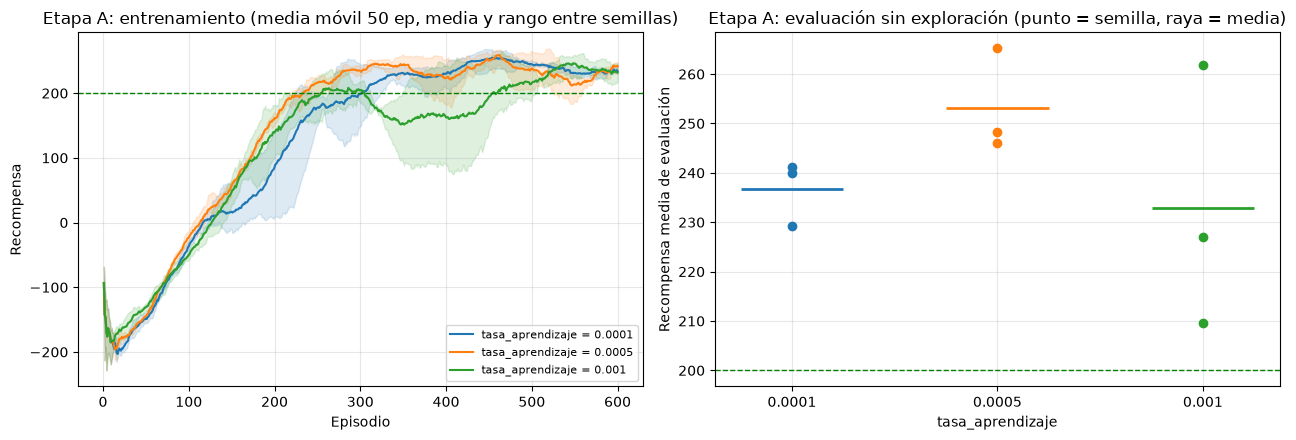

Etapa A: tasa_aprendizaje = 0.0005  (el valor vigente es el de mayor recompensa media)


In [12]:
# Calibración (3/5): etapa A, tasa de aprendizaje
config_vigente = dict(CONFIG_BASE)
config_vigente, resumen_A = correr_etapa('A', 'tasa_aprendizaje', [1e-4, 5e-4, 1e-3], config_vigente)

9 corridas (0 pendientes), 600 episodios cada una, 21 proceso(s)


,R_eval_media,R_eval_desv,exito_medio,R_entr_ult100,n_semillas,min_por_corrida,R_eval_por_semilla,R_eval_se
frecuencia_target,,,,,,,,
250,219.1,32.3,0.8,235.6,3,8.4,"187, 251, 219",18.7
1000,253.1,10.5,0.9,227.8,3,8.1,"265, 248, 246",6.1
4000,187.0,19.3,0.6,216.2,3,9.6,"173, 179, 209",11.1


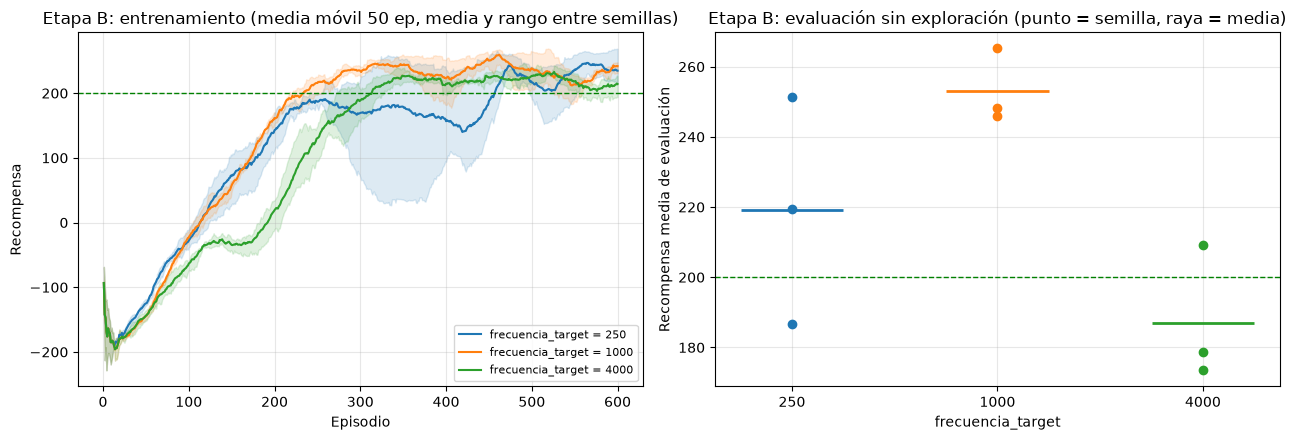

Etapa B: frecuencia_target = 1000  (el valor vigente es el de mayor recompensa media)


In [13]:
# Calibración (4/5): etapa B, frecuencia de copia de la red objetivo
config_vigente, resumen_B = correr_etapa('B', 'frecuencia_target', [250, 1_000, 4_000], config_vigente)

9 corridas (0 pendientes), 600 episodios cada una, 21 proceso(s)


,R_eval_media,R_eval_desv,exito_medio,R_entr_ult100,n_semillas,min_por_corrida,R_eval_por_semilla,R_eval_se
frac_exploracion,,,,,,,,
0.30,199.2,77.5,0.8,245.5,3,8.6,"247, 110, 241",44.7
0.50,229.9,33.8,0.8,237.8,3,8.9,"230, 196, 264",19.5
0.75,253.1,10.5,0.9,227.8,3,8.1,"265, 248, 246",6.1


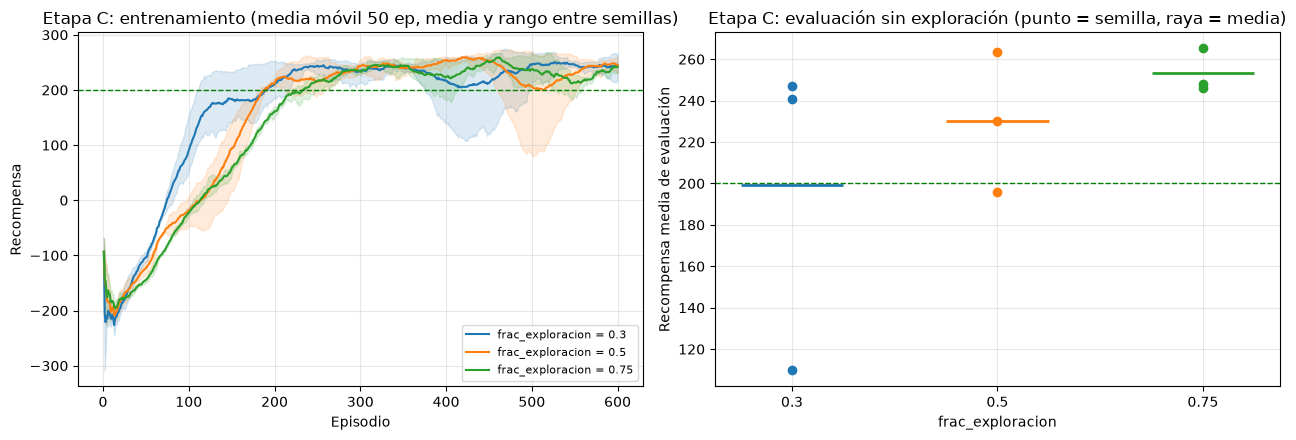

Etapa C: frac_exploracion = 0.75  (el valor vigente es el de mayor recompensa media)


,etapa,hiperparametro,valor,R_eval_media,R_eval_se,exito_medio,R_eval_por_semilla
0,A,tasa_aprendizaje,0.0001,236.8,3.8,0.87,"240, 229, 241"
1,A,tasa_aprendizaje,0.0005,253.1,6.1,0.94,"265, 248, 246"
2,A,tasa_aprendizaje,0.0010,232.8,15.4,0.83,"227, 210, 262"
3,B,frecuencia_target,250.0000,219.1,18.7,0.75,"187, 251, 219"
4,B,frecuencia_target,1000.0000,253.1,6.1,0.94,"265, 248, 246"
5,B,frecuencia_target,4000.0000,187.0,11.1,0.63,"173, 179, 209"
6,C,frac_exploracion,0.3000,199.2,44.7,0.77,"247, 110, 241"
7,C,frac_exploracion,0.5000,229.9,19.5,0.82,"230, 196, 264"
8,C,frac_exploracion,0.7500,253.1,6.1,0.94,"265, 248, 246"



Configuración elegida: {'frac_exploracion': 0.75, 'frecuencia_target': 1000, 'tasa_aprendizaje': 0.0005}


In [14]:
# Calibración (5/5): etapa C, duración de la exploración
config_vigente, resumen_C = correr_etapa('C', 'frac_exploracion', [0.3, 0.5, 0.75], config_vigente)

CONFIG_FINAL = dict(config_vigente)
(DIR_RESULTADOS / 'config_final.json').write_text(json.dumps(CONFIG_FINAL, indent=2))
tabla_calibracion = pd.concat([resumen_A, resumen_B, resumen_C]).reset_index(drop=True)
tabla_calibracion.to_csv(DIR_RESULTADOS / 'calibracion_resumen.csv', index=False)
display(tabla_calibracion[['etapa', 'hiperparametro', 'valor', 'R_eval_media', 'R_eval_se',
                           'exito_medio', 'R_eval_por_semilla']].round({'R_eval_media': 1, 'R_eval_se': 1,
                                                                        'exito_medio': 2}))
print(f"\nConfiguración elegida: {CONFIG_FINAL}")

## 7. Entrenamiento del agente DQN

Se entrena 1200 episodios de hasta 1000 pasos con la configuración elegida en la
calibración (sección 6b). `decaimiento_epsilon` se deduce de `frac_exploracion` para
este presupuesto de episodios.

**Sobre la parada temprana:** `entrenar_agente` acepta `umbral_resolucion` para
cortar cuando la media móvil de 100 episodios supera un valor.

In [15]:
# Entrenar el agente DQN con la configuración elegida en la calibración
EPISODIOS_FINAL = 20 if MODO_PRUEBA else 1200

if 'CONFIG_FINAL' not in globals():          # p. ej. en una sesión nueva, sin recalibrar
    ruta_config = DIR_RESULTADOS / 'config_final.json'
    CONFIG_FINAL = json.loads(ruta_config.read_text()) if ruta_config.exists() else dict(CONFIG_BASE)
kwargs_final = kwargs_agente(CONFIG_FINAL, EPISODIOS_FINAL)
print(f"Configuración: {CONFIG_FINAL} → decaimiento_epsilon = {kwargs_final['decaimiento_epsilon']:.5f}")

env = gym.make('LunarLander-v3')
agente_dqn = AgenteDQN(env.observation_space, env.action_space, semilla=SEMILLA, **kwargs_final)

print("\nEntrenando el agente DQN en LunarLander-v3...")
t_inicio_final = time.time()
recompensas_episodios, longitudes_episodios = entrenar_agente(
    agente_dqn, env,
    num_episodios=EPISODIOS_FINAL,
    max_pasos=1000,
    umbral_resolucion=None,   # ver nota sobre parada temprana más arriba
    semilla=SEMILLA,
    verbose=True,
)
TIEMPO_ENTRENAMIENTO = time.time() - t_inicio_final

env.close()

Configuración: {'frac_exploracion': 0.75, 'frecuencia_target': 1000, 'tasa_aprendizaje': 0.0005} → decaimiento_epsilon = 0.99490

Entrenando el agente DQN en LunarLander-v3...
Episodio    60 | Recompensa media (100 ep):  -137.10 | Longitud media:   97.2 | epsilon: 0.736 |     9s
Episodio   120 | Recompensa media (100 ep):   -89.29 | Longitud media:  123.5 | epsilon: 0.541 |    28s
Episodio   180 | Recompensa media (100 ep):   -41.53 | Longitud media:  275.7 | epsilon: 0.398 |    81s
Episodio   240 | Recompensa media (100 ep):     6.01 | Longitud media:  469.8 | epsilon: 0.293 |   166s
Episodio   300 | Recompensa media (100 ep):    84.34 | Longitud media:  700.7 | epsilon: 0.215 |   300s
Episodio   360 | Recompensa media (100 ep):   158.87 | Longitud media:  691.0 | epsilon: 0.158 |   401s
Episodio   420 | Recompensa media (100 ep):   203.84 | Longitud media:  482.4 | epsilon: 0.117 |   480s
Episodio   480 | Recompensa media (100 ep):   177.71 | Longitud media:  413.9 | epsilon: 0.086 |

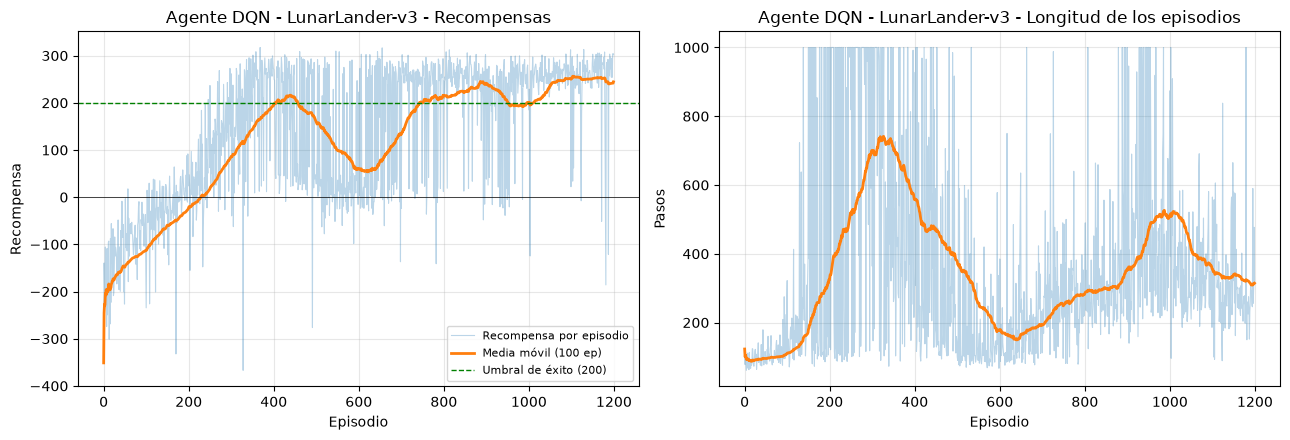

Resultados de los últimos 100 episodios de entrenamiento:
Recompensa promedio: 244.49
Tasa de éxito (R ≥ 200): 90.0%
Epsilon final: 0.010


In [16]:
# Graficar progreso del entrenamiento
graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                "Agente DQN - LunarLander-v3")

# Resultados del final del entrenamiento (todavía con exploración residual)
ultimos = np.array(recompensas_episodios[-100:])
print("Resultados de los últimos 100 episodios de entrenamiento:")
print(f"Recompensa promedio: {ultimos.mean():.2f}")
print(f"Tasa de éxito (R ≥ 200): {(ultimos >= UMBRAL_EXITO).mean():.1%}")
print(f"Epsilon final: {getattr(agente_dqn, 'epsilon', float('nan')):.3f}")

In [17]:
# Guardar el modelo, la curva de entrenamiento y los metadatos, para no reentrenar
agente_dqn.guardar(DIR_RESULTADOS / 'dqn_final.pt')
pd.DataFrame({'episodio': np.arange(1, len(recompensas_episodios) + 1),
              'recompensa': recompensas_episodios,
              'longitud': longitudes_episodios}).to_csv(DIR_RESULTADOS / 'entrenamiento_final.csv', index=False)
(DIR_RESULTADOS / 'entrenamiento_final.json').write_text(json.dumps({
    'config': CONFIG_FINAL, 'kwargs_agente': kwargs_final, 'episodios': EPISODIOS_FINAL,
    'semilla': SEMILLA, 'pasos_totales': int(np.sum(longitudes_episodios)),
    'tiempo_s': round(TIEMPO_ENTRENAMIENTO, 1), 'epsilon_final': agente_dqn.epsilon,
}, indent=2))
print(f"✓ Guardado en '{DIR_RESULTADOS}/': dqn_final.pt, entrenamiento_final.csv, entrenamiento_final.json "
      f"({TIEMPO_ENTRENAMIENTO / 60:.1f} min de entrenamiento)")

# Para recargar en otra sesión sin reentrenar:
# env = gym.make('LunarLander-v3')
# agente_dqn = AgenteDQN(env.observation_space, env.action_space, semilla=SEMILLA, **kwargs_final)
# agente_dqn.cargar(DIR_RESULTADOS / 'dqn_final.pt')

✓ Guardado en 'resultados/': dqn_final.pt, entrenamiento_final.csv, entrenamiento_final.json (20.1 min de entrenamiento)


## 8. Evaluación del agente entrenado

Se evalúan 200 episodios, sin exploración, sobre semillas fijas
(`10000 … 10199`). El agente aleatorio se vuelve a evaluar en la misma celda con
esas mismas semillas, de modo que ambos agentes enfrenten los mismos escenarios
iniciales.

In [18]:
# Evaluar el agente DQN entrenado
env = gym.make('LunarLander-v3')

print("Evaluando agente DQN entrenado (200 episodios, sin exploración)...")
resultados_dqn = evaluar_agente(agente_dqn, env, num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_dqn, "Agente DQN entrenado")

print("\nImplementación de referencia para comparar:")
resultados_aleatorio_200 = evaluar_agente(AgenteAleatorio(env.action_space, semilla=SEMILLA), env,
                                          num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio_200, "Agente aleatorio")

env.close()

Evaluando agente DQN entrenado (200 episodios, sin exploración)...

Agente DQN entrenado - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 98.0%
Recompensa promedio: 260.87
Recompensa mediana:  266.60
Desviación estándar: 36.89
Total de éxitos: 196 / 200

Implementación de referencia para comparar:

Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -183.12
Recompensa mediana:  -149.80
Desviación estándar: 111.95
Total de éxitos: 0 / 200


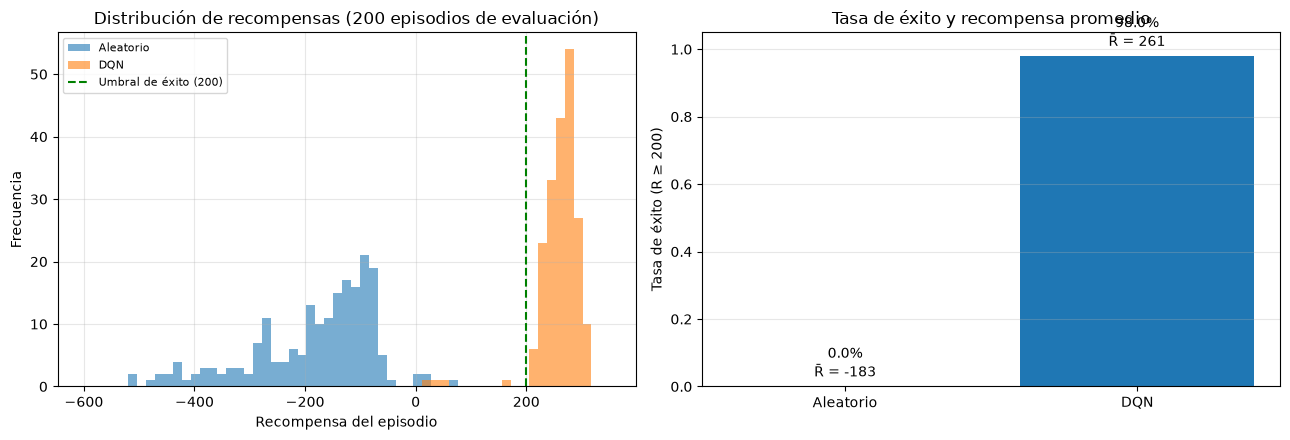

Tasa de éxito DQN:       98.0%
Tasa de éxito Aleatorio: 0.0%
Mejora en recompensa promedio: 444.0 puntos

Desglose de los 200 episodios del DQN:
  R ≥  200:  98.0%
  R ≥  150:  98.5%
  R ≥  100:  98.5%
  R ≥    0: 100.0%
  Episodios que se estrellan (R < -50): 0.0%


In [19]:
# Comparación gráfica: DQN vs. agente aleatorio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(-600, 350, 60)
ax1.hist(resultados_aleatorio_200['recompensas_totales'], bins=bins, alpha=0.6, label="Aleatorio")
ax1.hist(resultados_dqn['recompensas_totales'], bins=bins, alpha=0.6, label="DQN")
ax1.axvline(UMBRAL_EXITO, color='green', linestyle='--', label="Umbral de éxito (200)")
ax1.set_title("Distribución de recompensas (200 episodios de evaluación)")
ax1.set_xlabel("Recompensa del episodio")
ax1.set_ylabel("Frecuencia")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

nombres = ["Aleatorio", "DQN"]
tasas = [resultados_aleatorio_200['tasa_exito'], resultados_dqn['tasa_exito']]
promedios = [resultados_aleatorio_200['recompensa_promedio'], resultados_dqn['recompensa_promedio']]

barras = ax2.bar(nombres, tasas, color=['tab:gray', 'tab:blue'])
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Tasa de éxito (R ≥ 200)")
ax2.set_title("Tasa de éxito y recompensa promedio")
for barra, tasa, promedio in zip(barras, tasas, promedios):
    ax2.text(barra.get_x() + barra.get_width() / 2, tasa + 0.03,
             f"{tasa:.1%}\nR̄ = {promedio:.0f}", ha='center', fontsize=10)
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Tasa de éxito DQN:       {resultados_dqn['tasa_exito']:.1%}")
print(f"Tasa de éxito Aleatorio: {resultados_aleatorio_200['tasa_exito']:.1%}")
print(f"Mejora en recompensa promedio: "
      f"{resultados_dqn['recompensa_promedio'] - resultados_aleatorio_200['recompensa_promedio']:.1f} puntos")

# El umbral de 200 es un corte tajante: desglose de la cola de la distribución.
r_dqn = resultados_dqn['recompensas_totales']
print("\nDesglose de los 200 episodios del DQN:")
for corte in (200, 150, 100, 0):
    print(f"  R ≥ {corte:4d}: {(r_dqn >= corte).mean():6.1%}")
print(f"  Episodios que se estrellan (R < -50): {(r_dqn < -50).mean():.1%}")

In [20]:
# DQN vs. aleatorio: guardar los resultados por episodio y test pareado por escenario.
# Ambos agentes enfrentan los mismos 200 escenarios (semillas 10000…10199), así que cada
# episodio forma un par. Se usa Wilcoxon de rangos con signo, que no supone normalidad.
# El test compara esta política entrenada con la aleatoria; la variabilidad entre
# entrenamientos es tema del estudio de ablación (sección 11).
from scipy.stats import wilcoxon

r_dqn = resultados_dqn['recompensas_totales']
r_ale = resultados_aleatorio_200['recompensas_totales']
pd.DataFrame({'semilla_eval': 10_000 + np.arange(len(r_dqn)), 'dqn': r_dqn, 'aleatorio': r_ale}
             ).to_csv(DIR_RESULTADOS / 'evaluacion_final.csv', index=False)

dif = r_dqn - r_ale
prueba = wilcoxon(r_dqn, r_ale, alternative='two-sided')
rng_boot = np.random.default_rng(SEMILLA)
medias_boot = [rng_boot.choice(dif, size=len(dif)).mean() for _ in range(10_000)]
ic_bajo, ic_alto = np.percentile(medias_boot, [2.5, 97.5])
print(f"Diferencia media DQN − aleatorio: {dif.mean():.1f} puntos "
      f"(IC 95 % bootstrap: {ic_bajo:.1f} a {ic_alto:.1f})")
print(f"DQN mejor que el aleatorio en {(dif > 0).mean():.0%} de los escenarios")
print(f"Wilcoxon pareado: W = {prueba.statistic:.0f}, p = {prueba.pvalue:.2e}")
print(f"\nCriterio de la consigna (éxito > 10 %): "
      f"{'CUMPLIDO' if resultados_dqn['tasa_exito'] > 0.10 else 'NO cumplido'} "
      f"({resultados_dqn['tasa_exito']:.1%})")

Diferencia media DQN − aleatorio: 444.0 puntos (IC 95 % bootstrap: 427.3 a 460.4)
DQN mejor que el aleatorio en 100% de los escenarios
Wilcoxon pareado: W = 0, p = 1.44e-34

Criterio de la consigna (éxito > 10 %): CUMPLIDO (98.0%)


## 9. Visualización de la política aprendida

Se corren 10 episodios sin exploración sobre semillas sorteadas, sin elegir
los que salieron bien, y se arma un GIF con los diez en una grilla. Cada cuadro
muestra al terminar la recompensa del episodio, en verde si llegó al umbral de éxito
y en rojo si no.

  semilla 20892:  201 pasos, recompensa   288.8
  semilla 27739:  288 pasos, recompensa   262.9
  semilla 26545:  379 pasos, recompensa   223.4
  semilla 24388:  273 pasos, recompensa   276.3
  semilla 24330:  478 pasos, recompensa   258.1
  semilla 28585:  334 pasos, recompensa   277.9
  semilla 20859:  214 pasos, recompensa   238.1
  semilla 26973:  252 pasos, recompensa   307.8
  semilla 22014:  404 pasos, recompensa   239.5
  semilla 20941:  191 pasos, recompensa   253.3

10/10 episodios exitosos, recompensa media 262.6 → aterrizaje_dqn.gif


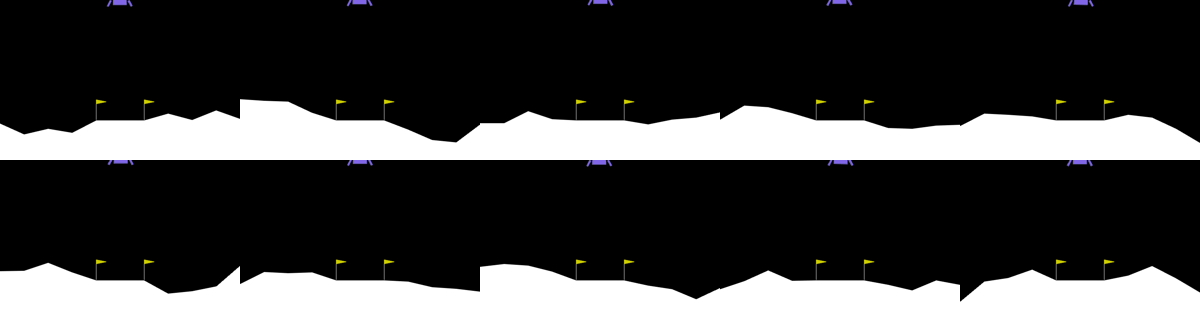

In [21]:
from PIL import Image, ImageDraw
from IPython.display import Image as MostrarImagen, display

ANCHO_CUADRO, ALTO_CUADRO = 240, 160

def _correr_episodio_render(agente, env, semilla, salto):
    """Corre un episodio renderizando y devuelve (cuadros, recompensa, pasos)."""
    estado, _ = env.reset(seed=semilla)
    cuadros, recompensa_total, paso = [], 0.0, 0
    while True:
        if paso % salto == 0:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
        estado, recompensa, terminado, truncado, _ = env.step(agente.elegir_accion(estado, explorar=False))
        recompensa_total += recompensa
        paso += 1
        if terminado or truncado:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
            break
    return cuadros, recompensa_total, paso


def _rotular(cuadro, recompensa, umbral):
    """Escribe la recompensa final sobre el cuadro: verde si es éxito, rojo si no."""
    cuadro = cuadro.copy()
    color = (40, 170, 70) if recompensa >= umbral else (210, 50, 50)
    ImageDraw.Draw(cuadro).text((6, 4), f"R = {recompensa:.0f}", fill=color)
    return cuadro


def grabar_episodios(agente, ruta_gif='aterrizaje_dqn.gif', semillas=range(10_000, 10_010),
                     columnas=5, salto=3, umbral=UMBRAL_EXITO):
    """Corre un episodio sin exploración por semilla y guarda un GIF con todos en
    una grilla. Los episodios que terminan antes quedan quietos en su último cuadro,
    rotulado con la recompensa obtenida."""
    env = gym.make('LunarLander-v3', render_mode='rgb_array')
    episodios = []
    try:
        for semilla in semillas:
            cuadros, recompensa_total, pasos = _correr_episodio_render(agente, env, semilla, salto)
            print(f"  semilla {semilla}: {pasos:4d} pasos, recompensa {recompensa_total:7.1f}")
            cuadros[-1] = _rotular(cuadros[-1], recompensa_total, umbral)
            episodios.append((cuadros, recompensa_total))
    finally:
        env.close()

    filas = -(-len(episodios) // columnas)
    largo = max(len(cuadros) for cuadros, _ in episodios)
    fotogramas = []
    for t in range(largo):
        lienzo = Image.new('RGB', (columnas * ANCHO_CUADRO, filas * ALTO_CUADRO), 'white')
        for i, (cuadros, _) in enumerate(episodios):
            lienzo.paste(cuadros[min(t, len(cuadros) - 1)],
                         ((i % columnas) * ANCHO_CUADRO, (i // columnas) * ALTO_CUADRO))
        fotogramas.append(lienzo)
    fotogramas[0].save(ruta_gif, save_all=True, append_images=fotogramas[1:], duration=50, loop=0)

    recompensas = np.array([r for _, r in episodios])
    print(f"\n{(recompensas >= umbral).sum()}/{len(recompensas)} episodios exitosos, "
          f"recompensa media {recompensas.mean():.1f} → {ruta_gif}")
    return ruta_gif, recompensas


# Semillas sorteadas, no elegidas: el GIF muestra los diez episodios salgan como salgan.
semillas_gif = np.random.default_rng(SEMILLA).integers(20_000, 30_000, size=10).tolist()
ruta, _ = grabar_episodios(agente_dqn, semillas=semillas_gif)
display(MostrarImagen(filename=ruta))

## 10. Qué aprendió la política

Se inspecciona la política greedy mediante **cortes bidimensionales** de la función de decisión. Para cada corte se varían dos componentes del estado y se fijan las seis restantes. Se comparan dos estados de referencia; los colores indican la acción elegida y la cruz el estado base. Son estados sintéticos, por lo que el análisis es descriptivo y no sustituye la evaluación por episodios.


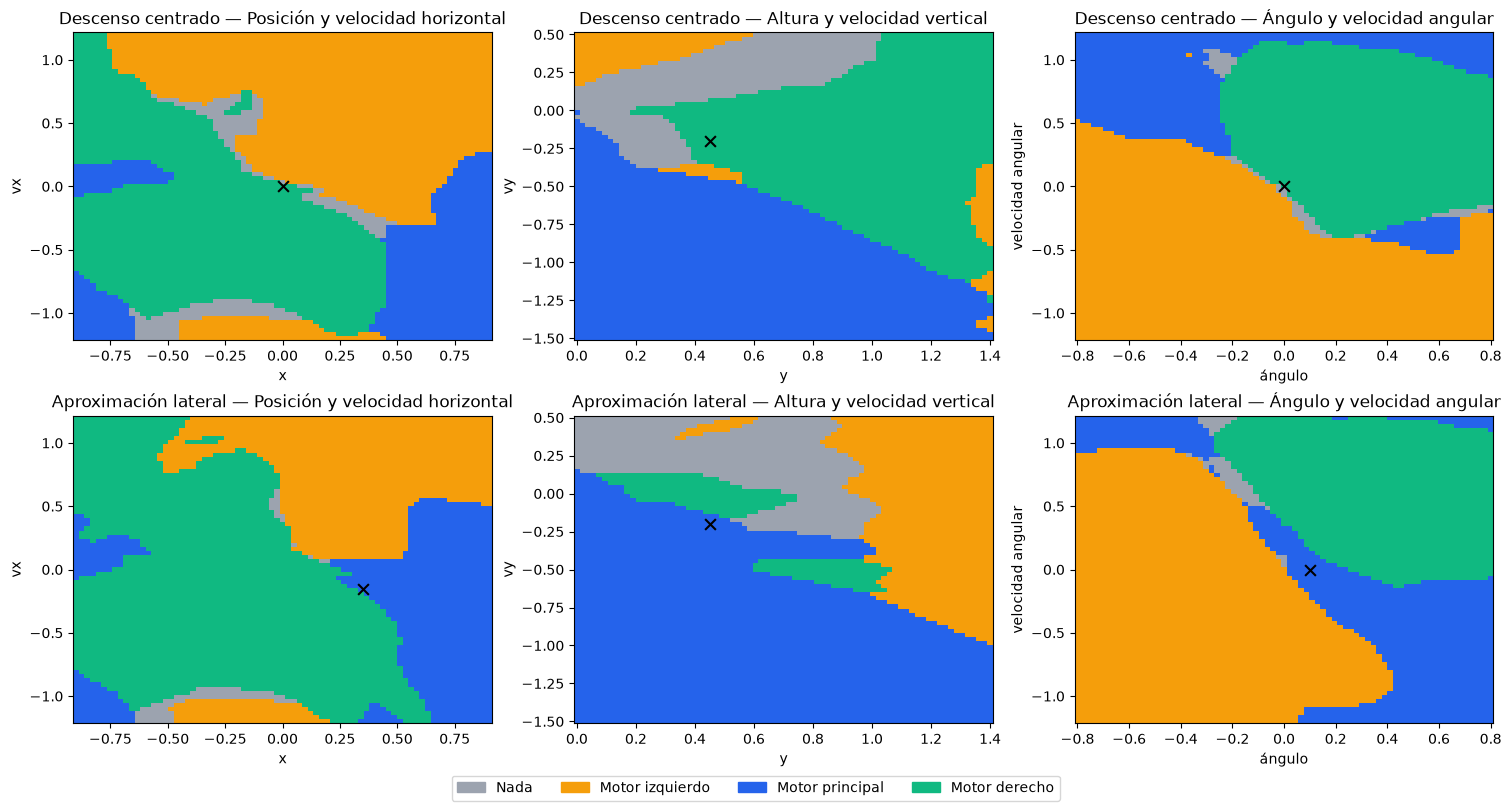

Interpretación: cada color indica la acción greedy elegida para un estado sintético.
La cruz marca el estado base; las demás variables se mantienen constantes.
Los cortes no prueban por sí solos estabilidad, causalidad ni éxito del aterrizaje.


In [22]:
# Cortes bidimensionales de la política greedy aprendida (sin exploración).
# Estado LunarLander: [x, y, vx, vy, ángulo, velocidad_angular, contacto_izq, contacto_der].
# Se fijan las otras seis variables y se varían dos para observar la acción preferida.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from pathlib import Path

# Utilizar el agente ya entrenado si existe; si no, cargar los pesos guardados.
if 'agente_dqn' not in globals():
    raiz_politica = Path.cwd()
    rutas_modelo = [raiz_politica / 'resultados' / 'dqn_final.pt',
                    raiz_politica.parent / 'resultados' / 'dqn_final.pt',
                    raiz_politica / 'modelos' / 'dqn_final.pt',
                    raiz_politica.parent / 'modelos' / 'dqn_final.pt']
    modelo = next((p for p in rutas_modelo if p.exists()), None)
    if modelo is None:
        raise FileNotFoundError('No hay agente entrenado ni dqn_final.pt. Ejecutar el entrenamiento o colocar el modelo en resultados/.')
    entorno_politica = gym.make('LunarLander-v3')
    try:
        agente_dqn = AgenteDQN(entorno_politica.observation_space,
                               entorno_politica.action_space, semilla=SEMILLA)
        agente_dqn.cargar(modelo)
    finally:
        entorno_politica.close()
    print('Modelo cargado desde:', modelo)

NOMBRES_ACCIONES = ['Nada', 'Motor izquierdo', 'Motor principal', 'Motor derecho']
NOMBRES_ESTADO = ['x', 'y', 'vx', 'vy', 'ángulo', 'velocidad angular',
                  'contacto izquierdo', 'contacto derecho']

# Estados sintéticos; los mapas describen la función aprendida, no frecuencias de visita.
# Dos escenarios: descenso centrado y aproximación lateral, ambos sin contacto con el suelo.
ESCENARIOS = [
    ('Descenso centrado', np.array([0., 0.45, 0., -0.2, 0., 0., 0., 0.], dtype=np.float32)),
    ('Aproximación lateral', np.array([0.35, 0.45, -0.15, -0.2, 0.1, 0., 0., 0.], dtype=np.float32)),
]
CORTES = [
    ('Posición y velocidad horizontal', 0, 2, (-0.9, 0.9), (-1.2, 1.2)),
    ('Altura y velocidad vertical', 1, 3, (0.0, 1.4), (-1.5, 0.5)),
    ('Ángulo y velocidad angular', 4, 5, (-0.8, 0.8), (-1.2, 1.2)),
]
colores = ListedColormap(['#9ca3af', '#f59e0b', '#2563eb', '#10b981'])
norm = BoundaryNorm(np.arange(-0.5, 4.5, 1), colores.N)
fig, ejes = plt.subplots(len(ESCENARIOS), len(CORTES), figsize=(15, 8), constrained_layout=True)
for fila, (escenario, estado_base) in enumerate(ESCENARIOS):
    for columna, (titulo, ix, iy, lim_x, lim_y) in enumerate(CORTES):
        xx = np.linspace(*lim_x, 75)
        yy = np.linspace(*lim_y, 75)
        X, Y = np.meshgrid(xx, yy)
        estados = np.repeat(estado_base[None, :], X.size, axis=0)
        estados[:, ix] = X.ravel()
        estados[:, iy] = Y.ravel()
        # Se utiliza elegir_accion para no asumir detalles internos de la red.
        acciones = np.array([agente_dqn.elegir_accion(s, explorar=False)
                             for s in estados]).reshape(X.shape)
        ax = ejes[fila, columna]
        ax.pcolormesh(X, Y, acciones, cmap=colores, norm=norm, shading='auto')
        ax.scatter([estado_base[ix]], [estado_base[iy]], marker='x', c='black', s=60)
        ax.set_title(f'{escenario} — {titulo}')
        ax.set_xlabel(NOMBRES_ESTADO[ix])
        ax.set_ylabel(NOMBRES_ESTADO[iy])
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=colores(i), label=nombre)
                    for i, nombre in enumerate(NOMBRES_ACCIONES)],
           loc='outside lower center', ncol=4)
plt.show()

print('Interpretación: cada color indica la acción greedy elegida para un estado sintético.')
print('La cruz marca el estado base; las demás variables se mantienen constantes.')
print('Los cortes no prueban por sí solos estabilidad, causalidad ni éxito del aterrizaje.')


## 11. Estudio de ablación

Las secciones anteriores muestran que el DQN completo funciona, pero no *cuánto*
aporta cada una de sus piezas. Una **ablación** responde eso: se reentrena el
agente desde cero desactivando (o degradando) un componente por vez y se mide
cuánto cae el desempeño respecto de la configuración completa.

Comparen el DQN completo contra, como mínimo, tres variantes correspondientes a
quitar características de DQN. Cada configuración se entrena con varias semillas y
se evalúa sobre las mismas semillas de evaluación, sin exploración. Reporten para
cada variante la recompensa de evaluación por semilla y comparen contra el DQN
completo con un test estadístico adecuado.


### 11.1. Protocolo experimental y reproducibilidad

Se comparan cuatro variantes: **DQN completo**, **sin replay**, **sin red objetivo** y **sin ambas técnicas**. Se emplean 10 semillas independientes de entrenamiento, 1200 episodios por semilla y 50 escenarios de evaluación comunes (`60000`–`60049`), con política *greedy* (`explorar=False`). La unidad experimental para la inferencia estadística es la **semilla de entrenamiento**, no cada episodio evaluado.

Se conserva la implementación de `AgenteDQN` de la sección 6, incluidos los parámetros calibrados (`lr=0.0005`, sincronización de target cada 1000 actualizaciones y fracción de exploración 0.75). **Sin replay** implica aprendizaje online con lote de tamaño 1 y sin calentamiento, mientras que **con replay** usa lotes de 64 y 1000 pasos de calentamiento. Esta diferencia de régimen de optimización debe considerarse al interpretar la ablación.

La ejecución experimental ya se realizó y los CSV se conservan en `resultados/ablacion_companera/final/`. La celda de entrenamiento siguiente está desactivada por defecto para no repetir 40 entrenamientos.

In [2]:
# Configuración y rutas de la ablación (independiente de las celdas de calibración)
from pathlib import Path
import json, csv, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, rankdata
from IPython.display import display

# Compatible con Jupyter iniciado desde la raíz o desde notebooks/
RAIZ_ABL = Path.cwd()
if not (RAIZ_ABL / 'notebooks').is_dir():
    RAIZ_ABL = RAIZ_ABL.parent
CARPETA_ABL = RAIZ_ABL / 'resultados' / 'ablacion_companera' / 'final'
CONFIG_ABL = RAIZ_ABL / 'modelos' / 'config_final.json'
VARIANTES_ABL = {'DQN completo': (True, True), 'Sin replay': (False, True),
                 'Sin target': (True, False), 'Sin ambos': (False, False)}
SEMILLAS_ABL = [11, 23, 37, 41, 53, 67, 71, 83, 97, 109]
SEMILLA_EVAL_ABL = 60000
N_EVAL_ABL = 50
EPISODIOS_ABL = 1200
if not CONFIG_ABL.exists():
    alternativa = RAIZ_ABL / 'resultados' / 'config_final.json'
    alternativa_notebooks = RAIZ_ABL / 'notebooks' / 'resultados' / 'config_final.json'
    origen_config = next((p for p in [alternativa, alternativa_notebooks] if p.exists()), None)
    if origen_config is None:
        raise FileNotFoundError(f'Falta {CONFIG_ABL}. Ejecutar calibración o proporcionar config_final.json.')
    CONFIG_ABL.parent.mkdir(parents=True, exist_ok=True)
    CONFIG_ABL.write_text(origen_config.read_text(encoding='utf-8'), encoding='utf-8')
    print('Configuración copiada desde:', origen_config)
config_abl = json.loads(CONFIG_ABL.read_text(encoding='utf-8'))
assert config_abl == {'frac_exploracion': 0.75, 'frecuencia_target': 1000,
                      'tasa_aprendizaje': 0.0005}, 'Configuración diferente a la validada'
print('Resultados:', CARPETA_ABL)
print('Configuración:', config_abl)

Resultados: /home/ismael/AprendizajeAutomatico/resultados/ablacion_companera/final
Configuración: {'frac_exploracion': 0.75, 'frecuencia_target': 1000, 'tasa_aprendizaje': 0.0005}


### 11.2. Código de entrenamiento (ejecución opcional)

La celda reproduce las cuatro variantes mediante `AgenteDQN`, `entrenar_agente` y `evaluar_agente` definidos anteriormente en este mismo notebook. **Por defecto no ejecuta entrenamientos**. Para reproducir desde cero, ejecutar primero las celdas que definen esas funciones, establecer `EJECUTAR_ABLACION = True` y ejecutar esta celda. Los resultados se escriben incrementalmente y las corridas completas se omiten al reanudar.

Para la evaluación se usa la misma secuencia de 50 semillas para todos los modelos. El procedimiento secuencial evita problemas de multiprocessing dentro de Jupyter; puede tardar varias horas.

In [29]:
EJECUTAR_ABLACION = False  # Cambiar a True SOLO si se desea repetir el experimento completo.

def _guardar_csv_abl(ruta, filas, columnas):
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temporal = ruta.with_suffix('.tmp')
    with temporal.open('w', newline='', encoding='utf-8') as f:
        escritor = csv.DictWriter(f, fieldnames=columnas)
        escritor.writeheader()
        escritor.writerows(filas)
    os.replace(temporal, ruta)

def _kwargs_abl(config, episodios):
    kw = {k: v for k, v in config.items() if k != 'frac_exploracion'}
    n = max(1.0, config['frac_exploracion'] * episodios)
    kw.update(epsilon_inicial=1.0, epsilon_final=0.01,
              decaimiento_epsilon=(0.01 / 1.0) ** (1.0 / n))
    return kw

def ejecutar_ablacion_notebook():
    destino = CARPETA_ABL / 'ablacion.csv'
    columnas = ['configuracion', 'semilla_entrenamiento', 'semilla_evaluacion',
                'recompensa', 'exito']
    spec = {'config': config_abl, 'episodios': EPISODIOS_ABL, 'n_eval': N_EVAL_ABL,
            'eval_seed': SEMILLA_EVAL_ABL, 'semillas': SEMILLAS_ABL,
            'variantes': VARIANTES_ABL}
    metadatos = CARPETA_ABL / 'configuracion.json'
    if metadatos.exists() and json.loads(metadatos.read_text()) != spec:
        raise ValueError('La configuración no coincide con los resultados existentes')
    CARPETA_ABL.mkdir(parents=True, exist_ok=True)
    metadatos.write_text(json.dumps(spec, indent=2), encoding='utf-8')
    filas = list(csv.DictReader(destino.open(newline='', encoding='utf-8'))) if destino.exists() else []
    for indice, (nombre, (replay, target)) in enumerate(VARIANTES_ABL.items()):
        for semilla in SEMILLAS_ABL:
            prev = [f for f in filas if f['configuracion'] == nombre
                    and int(f['semilla_entrenamiento']) == semilla]
            curva = CARPETA_ABL / f'curva_{indice}_{semilla}.csv'
            if len(prev) == N_EVAL_ABL and curva.exists():
                print('Ya completado:', nombre, semilla)
                continue
            filas = [f for f in filas if not (f['configuracion'] == nombre
                     and int(f['semilla_entrenamiento']) == semilla)]
            env_abl = gym.make('LunarLander-v3')
            try:
                agente_abl = AgenteDQN(env_abl.observation_space, env_abl.action_space,
                                      semilla=semilla, usar_replay=replay,
                                      usar_target=target,
                                      **_kwargs_abl(config_abl, EPISODIOS_ABL))
                recompensas, longitudes = entrenar_agente(
                    agente_abl, env_abl, num_episodios=EPISODIOS_ABL,
                    max_pasos=1000, umbral_resolucion=None,
                    semilla=semilla, verbose=False)
                evaluacion = evaluar_agente(agente_abl, env_abl,
                    num_episodios=N_EVAL_ABL, semilla=SEMILLA_EVAL_ABL)
            finally:
                env_abl.close()
            curva_filas = [{'episodio': i, 'recompensa': float(r), 'longitud': int(l)}
                           for i, (r, l) in enumerate(zip(recompensas, longitudes), 1)]
            _guardar_csv_abl(curva, curva_filas, ['episodio', 'recompensa', 'longitud'])
            nuevas = [{'configuracion': nombre, 'semilla_entrenamiento': semilla,
                       'semilla_evaluacion': SEMILLA_EVAL_ABL + i,
                       'recompensa': float(r), 'exito': int(r >= 200)}
                      for i, r in enumerate(evaluacion['recompensas_totales'])]
            filas.extend(nuevas)
            _guardar_csv_abl(destino, filas, columnas)
            print('Completado:', nombre, semilla, 'media:', round(np.mean([x['recompensa'] for x in nuevas]), 2))

if EJECUTAR_ABLACION:
    ejecutar_ablacion_notebook()
else:
    print('Entrenamiento desactivado: se utilizarán los resultados guardados.')

Entrenamiento desactivado: se utilizarán los resultados guardados.


### 11.3. Resultados de evaluación y validación de datos

Se agregan las 50 recompensas de evaluación de cada modelo para obtener **una observación por semilla de entrenamiento**. Se verifican las 40 combinaciones, las 50 evaluaciones por combinación y la ausencia de duplicados.

In [3]:
archivo_abl = CARPETA_ABL / 'ablacion.csv'
if not archivo_abl.exists():
    raise FileNotFoundError(f'No se encontró {archivo_abl}. Copiar la carpeta de resultados al proyecto.')
df_abl = pd.read_csv(archivo_abl)
claves_abl = ['configuracion', 'semilla_entrenamiento', 'semilla_evaluacion']
assert not df_abl.duplicated(claves_abl).any(), 'Evaluaciones duplicadas'
conteos_abl = df_abl.groupby(['configuracion', 'semilla_entrenamiento']).size()
assert len(conteos_abl) == 40 and (conteos_abl == N_EVAL_ABL).all(), 'Resultados incompletos'
assert set(df_abl['configuracion']) == set(VARIANTES_ABL), 'Variantes inesperadas'
assert set(df_abl['semilla_entrenamiento']) == set(SEMILLAS_ABL), 'Semillas inesperadas'
assert set(df_abl['semilla_evaluacion']) == set(range(SEMILLA_EVAL_ABL, SEMILLA_EVAL_ABL+N_EVAL_ABL))
por_semilla_abl = (df_abl.groupby(['configuracion', 'semilla_entrenamiento'])
    .agg(recompensa_media=('recompensa', 'mean'), tasa_exito=('exito', 'mean'))
    .reset_index())
resumen_abl = (por_semilla_abl.groupby('configuracion')
    .agg(media=('recompensa_media', 'mean'), desviacion=('recompensa_media', 'std'),
         tasa_exito=('tasa_exito', 'mean'))
    .reindex(list(VARIANTES_ABL)))
print('Entrenamientos:', len(conteos_abl), '| Evaluaciones:', len(df_abl))
display(resumen_abl.round(3))

Entrenamientos: 40 | Evaluaciones: 2000


,media,desviacion,tasa_exito
configuracion,,,
DQN completo,222.530,50.586,0.756
Sin replay,-562.277,353.624,0.002
Sin target,-82.817,385.694,0.344
Sin ambos,189.584,56.039,0.682


### 11.4. Curvas de aprendizaje y dispersión entre semillas

Cada curva se suaviza mediante una media móvil causal de 100 episodios. Se representa la media entre las diez semillas y una banda de ±1 desviación estándar **entre semillas**. La banda es descriptiva, no un intervalo de confianza.

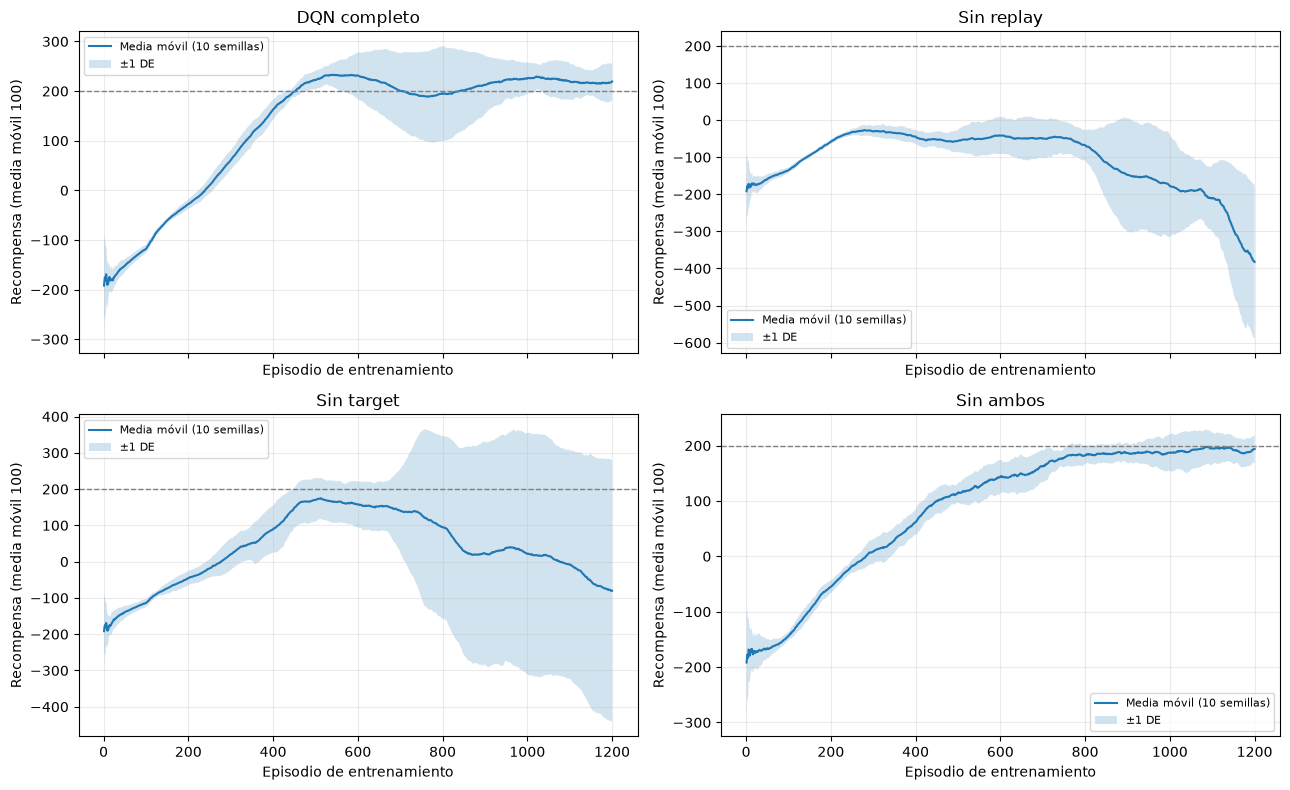

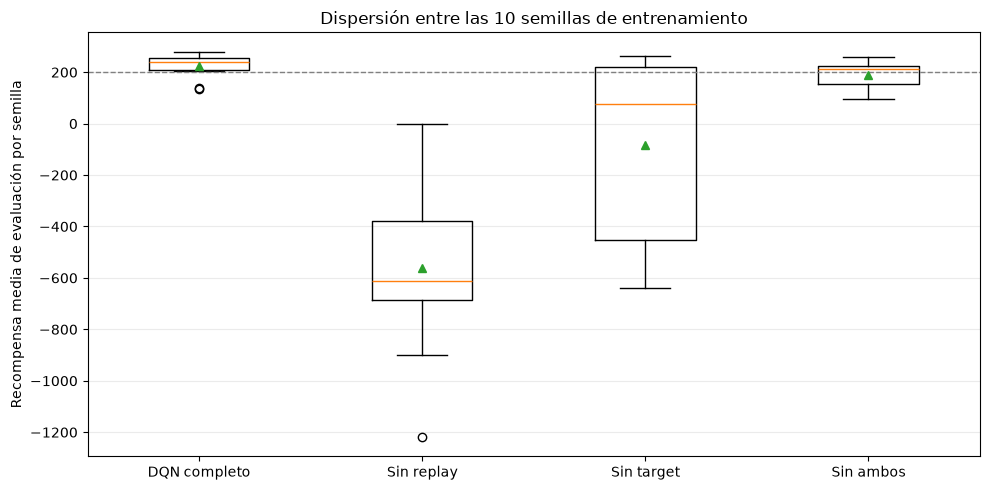

In [31]:
fig, ejes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for eje, (indice, nombre) in zip(ejes.flat, enumerate(VARIANTES_ABL)):
    curvas = []
    for semilla in SEMILLAS_ABL:
        ruta = CARPETA_ABL / f'curva_{indice}_{semilla}.csv'
        if not ruta.exists():
            raise FileNotFoundError(f'Falta curva de entrenamiento: {ruta}')
        curva = pd.read_csv(ruta)
        assert len(curva) == EPISODIOS_ABL, f'Curva incompleta: {ruta}'
        suavizada = curva['recompensa'].rolling(100, min_periods=1).mean().to_numpy()
        curvas.append(suavizada)
    valores = np.stack(curvas)
    x = np.arange(1, EPISODIOS_ABL+1)
    media = valores.mean(axis=0)
    desv = valores.std(axis=0, ddof=1)
    eje.plot(x, media, label='Media móvil (10 semillas)')
    eje.fill_between(x, media-desv, media+desv, alpha=0.2, label='±1 DE')
    eje.axhline(200, linestyle='--', color='gray', linewidth=1)
    eje.set_title(nombre)
    eje.set_xlabel('Episodio de entrenamiento')
    eje.set_ylabel('Recompensa (media móvil 100)')
    eje.grid(alpha=0.25)
    eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
orden = list(VARIANTES_ABL)
series = [por_semilla_abl.loc[por_semilla_abl.configuracion == v, 'recompensa_media'].to_numpy()
          for v in orden]
ax.boxplot(series, tick_labels=orden, showmeans=True)
ax.axhline(200, linestyle='--', color='gray', linewidth=1, label='Umbral 200')
ax.set_ylabel('Recompensa media de evaluación por semilla')
ax.set_title('Dispersión entre las 10 semillas de entrenamiento')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

### 11.5. Comparaciones pareadas y significación estadística

Para cada semilla se calcula `recompensa_media(variante) − recompensa_media(DQN completo)`. Se aplica **Wilcoxon bilateral exacto** y ajuste de **Holm** para tres comparaciones. Se estima un IC bootstrap percentil del 95 % para la **diferencia media**, remuestreando pares de semillas (20 000 réplicas). Se reporta además la **correlación biserial de rangos pareados** (signo positivo: ventaja de la variante). El contraste de Wilcoxon y el IC bootstrap responden a estimandos distintos; sus resultados no deben interpretarse como equivalentes.

Recompensa media de evaluación por semilla de entrenamiento (50 episodios por celda):


configuracion,DQN completo,Sin replay,Sin target,Sin ambos
semilla_entrenamiento,,,,
11,255.4,-379.0,262.1,230.0
23,217.3,-900.8,16.2,139.5
37,280.2,-1217.3,-638.2,213.8
41,260.6,-686.3,80.3,212.3
53,254.7,-3.3,247.9,233.3
67,232.8,-380.6,-638.2,97.5
71,138.5,-619.1,-609.4,210.8
83,205.9,-604.8,250.3,103.0
97,132.8,-151.8,131.6,198.3


,comparacion,diferencia_media,diferencia_mediana,W,p,biserial_rangos,IC95_inferior,IC95_superior,p_holm,significativo_05
0,Sin replay,-784.8067,-784.0935,0.0,0.0020,-1.0000,-1005.5585,-571.2534,0.0059,True
1,Sin target,-305.3471,-179.2396,6.0,0.0273,-0.7818,-547.0114,-99.1652,0.0547,False
2,Sin ambos,-32.9459,-36.8305,13.0,0.1602,-0.5273,-71.3898,7.2353,0.1602,False


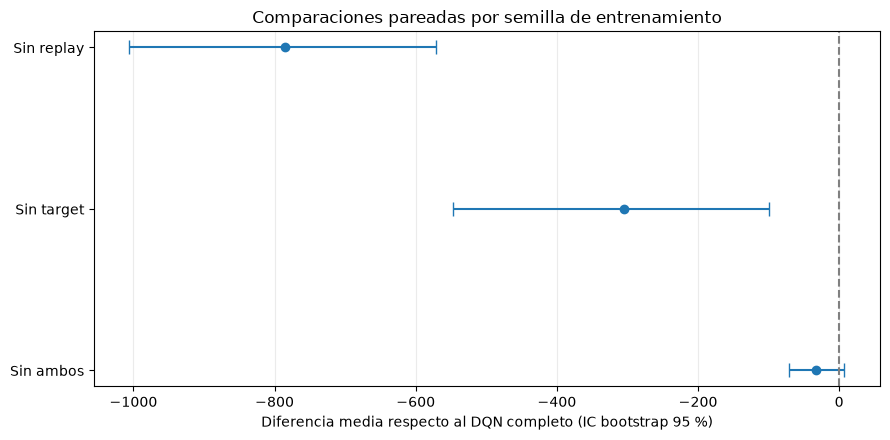

In [4]:
# Recompensa media de evaluación por semilla de entrenamiento
matriz_abl = por_semilla_abl.pivot(
    index='semilla_entrenamiento',
    columns='configuracion',
    values='recompensa_media'
).sort_index()

# Mantener el mismo orden de variantes que en el resto del análisis
matriz_abl = matriz_abl[list(VARIANTES_ABL)]

# Mostrar la tabla solicitada por la consigna
print('Recompensa media de evaluación por semilla de entrenamiento (50 episodios por celda):')
display(matriz_abl.round(1))

# Guardar la tabla en CSV
matriz_abl.round(3).to_csv(
    CARPETA_ABL / 'recompensa_por_semilla_notebook.csv'
)

# Continuar con las pruebas estadísticas
referencia_abl = matriz_abl['DQN completo']
rng_abl = np.random.default_rng(2026)
comparaciones_abl = []
for nombre in ['Sin replay', 'Sin target', 'Sin ambos']:
    d = (matriz_abl[nombre] - referencia_abl).to_numpy()
    # El método exacto estándar requiere diferencias no nulas y sin empates en |d|.
    assert np.all(d != 0) and len(np.unique(np.abs(d))) == len(d),         f'Empates o ceros en {nombre}: revisar método exacto'
    test = wilcoxon(d, alternative='two-sided', method='exact')
    rangos = rankdata(np.abs(d))
    w_pos = rangos[d > 0].sum()
    w_neg = rangos[d < 0].sum()
    biserial = (w_pos - w_neg) / (w_pos + w_neg)
    muestras = d[rng_abl.integers(0, len(d), size=(20000, len(d)))].mean(axis=1)
    li, ls = np.quantile(muestras, [0.025, 0.975])
    comparaciones_abl.append(dict(comparacion=nombre, diferencia_media=d.mean(),
        diferencia_mediana=np.median(d), W=test.statistic, p=test.pvalue,
        biserial_rangos=biserial, IC95_inferior=li, IC95_superior=ls))
pruebas_abl = pd.DataFrame(comparaciones_abl)
orden_p = np.argsort(pruebas_abl.p.to_numpy())
p_ord = pruebas_abl.p.to_numpy()[orden_p]
ajustados = np.minimum(1, np.maximum.accumulate(p_ord * (len(p_ord) - np.arange(len(p_ord)))))
p_holm = np.empty(len(ajustados))
p_holm[orden_p] = ajustados
pruebas_abl['p_holm'] = p_holm
pruebas_abl['significativo_05'] = p_holm < 0.05
display(pruebas_abl.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(pruebas_abl))
centros = pruebas_abl.diferencia_media.to_numpy()
err = np.vstack([centros-pruebas_abl.IC95_inferior.to_numpy(),
                 pruebas_abl.IC95_superior.to_numpy()-centros])
ax.errorbar(centros, y, xerr=err, fmt='o', capsize=5)
ax.axvline(0, color='gray', linestyle='--')
ax.set_yticks(y, pruebas_abl.comparacion)
ax.invert_yaxis()
ax.set_xlabel('Diferencia media respecto al DQN completo (IC bootstrap 95 %)')
ax.set_title('Comparaciones pareadas por semilla de entrenamiento')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

# Exportar tablas derivadas sin alterar los CSV experimentales originales.
por_semilla_abl.to_csv(CARPETA_ABL / 'resumen_semillas_notebook.csv', index=False)
resumen_abl.to_csv(CARPETA_ABL / 'resumen_configuraciones_notebook.csv')
pruebas_abl.to_csv(CARPETA_ABL / 'pruebas_estadisticas_notebook.csv', index=False)

### 11.6. Guía para la discusión de resultados

La interpretación debe distinguir **rendimiento promedio**, **estabilidad entre semillas** y **significación estadística**. En particular, conviene examinar: (a) si quitar replay o target perjudica consistentemente las recompensas pareadas; (b) si la variante sin ambas técnicas presenta resultados heterogéneos o comparables al modelo completo; y (c) la diferencia entre recompensa media y tasa de éxito.

**Limitaciones:** 10 semillas de entrenamiento; intervalos bootstrap aproximados; la ablación sin replay también cambia tamaño de lote y calentamiento; las comparaciones individuales contra el DQN completo **no constituyen una prueba factorial de interacción**. La discusión final debe redactarse a partir de las tablas y figuras efectivamente calculadas.